---
## 1. Environment Setup, Reproducibility, & Shared Pipeline Modules
We configure deterministic execution (`SEED = 42`), writable temporary cache directories, bounded worker pools (`LOKY_MAX_CPU_COUNT=4`), and shared helper functions including subject-grouped calibration (`calibrate_teacher_oof`), independent grouped calibration-validation (`validate_calibration_grouped`), controlled iterative self-training (`run_iterative_self_training`), 35-config inner CV (`evaluate_35_configs_grouped_cv`), and 1,000-iteration cluster bootstrap CIs (`subject_cluster_bootstrap_ci`).

In [1]:
import os
import time
import pickle
import random
import tempfile
import warnings
from pathlib import Path
from datetime import datetime, timezone
from zoneinfo import ZoneInfo

warnings.filterwarnings('ignore')

os.environ['LOKY_MAX_CPU_COUNT'] = '4'
os.environ['MPLCONFIGDIR'] = os.path.join(tempfile.gettempdir(), 'matplotlib')
os.environ['KERAS_HOME'] = os.path.join(tempfile.gettempdir(), 'keras')
os.environ['PYTHONHASHSEED'] = '42'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import medfilt, find_peaks

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix
)
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import NearMiss, RandomUnderSampler
from imblearn.combine import SMOTETomek

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10
})

SAMPLERS_CFG = [
    ('None', None),
    ('CostSensitive', 'class_weight'),
    ('SMOTE', lambda: SMOTE(random_state=SEED)),
    ('ADASYN', lambda: ADASYN(random_state=SEED)),
    ('SMOTETomek', lambda: SMOTETomek(random_state=SEED)),
    ('RandomUnder', lambda: RandomUnderSampler(random_state=SEED)),
    ('NearMiss', lambda: NearMiss())
]
MODEL_NAMES = ['LR', 'RF', 'HGBC', 'SVC', 'MLP']


def make_classifier(name: str, cost_sensitive: bool = False):
    '''Instantiate a deterministic classifier matching the 35-config grid.'''
    cw = 'balanced' if cost_sensitive else None
    if name == 'LR':
        return LogisticRegression(solver='liblinear', random_state=SEED, class_weight=cw)
    if name == 'RF':
        return RandomForestClassifier(n_estimators=100, random_state=SEED, class_weight=cw)
    if name == 'HGBC':
        return HistGradientBoostingClassifier(random_state=SEED, class_weight=cw)
    if name == 'SVC':
        return SVC(probability=True, random_state=SEED, class_weight=cw)
    if name == 'MLP':
        return MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=SEED, early_stopping=True)
    raise ValueError(f"Unknown classifier: {name}")


def calibrate_teacher_oof(
    model_factory,
    X: np.ndarray,
    y: np.ndarray,
    groups: np.ndarray,
    n_splits: int = 4,
    target_prec: dict = None,
    min_recall: float = 0.20,
    min_tau: float = 0.80,
    return_diagnostics: bool = False
):
    '''
    Subject-grouped OOF confidence threshold calibration.
    Scalers fit strictly inside each calibration fold. Enforces minimal
    confidence margin (t >= min_tau) and precision target (default {0: 0.95, 1: 0.75})
    with fallback to maximum achievable OOF precision (r >= min_recall).
    '''
    if target_prec is None:
        target_prec = {0: 0.95, 1: 0.75}

    gkf = GroupKFold(n_splits=n_splits)
    oof_probs = np.zeros((len(y), 2))
    for tr_idx, va_idx in gkf.split(X, y, groups=groups):
        sc = StandardScaler()
        clf = model_factory().fit(sc.fit_transform(X[tr_idx]), y[tr_idx])
        oof_probs[va_idx] = clf.predict_proba(sc.transform(X[va_idx]))

    thresholds, diag = {}, {}
    for c in [0, 1]:
        p, r, t = precision_recall_curve((y == c).astype(int), oof_probs[:, c])
        valid_base = np.where((t >= min_tau) & (r[:-1] >= min_recall))[0]
        if len(valid_base) == 0:
            valid_base = np.where(t >= min_tau)[0]
        if len(valid_base) == 0:
            thresholds[c] = max(0.75, min_tau)
            diag[c] = {'target_met': False, 'oof_prec': float('nan'), 'oof_rec': float('nan')}
            continue
        valid_target = valid_base[p[valid_base] >= target_prec[c]]
        idx = valid_target[0] if len(valid_target) > 0 else valid_base[np.argmax(p[valid_base])]
        thresholds[c] = float(t[idx])
        diag[c] = {'target_met': bool(len(valid_target) > 0), 'oof_prec': float(p[idx]), 'oof_rec': float(r[idx])}

    return (thresholds, diag) if return_diagnostics else thresholds


def wilson_ci(k: int, n: int, z: float = 1.96):
    '''Two-sided 95% Wilson score confidence interval for accepted-window precision.'''
    if n == 0:
        return (float('nan'), float('nan'))
    p = k / n
    denom = 1.0 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = (z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)) / denom
    return (max(0.0, center - half), min(1.0, center + half))


def validate_calibration_grouped(
    model_factory,
    X: np.ndarray,
    y: np.ndarray,
    groups: np.ndarray,
    target_prec: dict,
    outer_splits: int = 4,
    inner_splits: int = 3,
    min_recall: float = 0.20,
    min_tau: float = 0.80,
    n_boot: int = 1000,
    seed: int = SEED
):
    '''
    Nested grouped calibration-validation loop:
    Selects thresholds inside cal_train subjects via inner GroupKFold, then evaluates
    accepted predictions on completely unseen cal_val subjects to obtain unbiased
    Independent Cal-Val Precision, Coverage, Wilson 95% CIs, and Cluster Bootstrap 95% CIs.
    '''
    gkf_out = GroupKFold(n_splits=outer_splits)
    val_y_true = np.zeros(len(y), dtype=int)
    val_pred = np.zeros(len(y), dtype=int)
    val_prob = np.zeros((len(y), 2))
    val_tau0 = np.zeros(len(y))
    val_tau1 = np.zeros(len(y))
    sel_prec_0, sel_prec_1 = [], []
    tau0_folds, tau1_folds = [], []
    target_met_0, target_met_1 = [], []

    for tr_idx, va_idx in gkf_out.split(X, y, groups=groups):
        th, diag = calibrate_teacher_oof(
            model_factory, X[tr_idx], y[tr_idx], groups[tr_idx],
            n_splits=inner_splits, target_prec=target_prec,
            min_recall=min_recall, min_tau=min_tau, return_diagnostics=True
        )
        sel_prec_0.append(diag[0]['oof_prec'])
        sel_prec_1.append(diag[1]['oof_prec'])
        target_met_0.append(diag[0]['target_met'])
        target_met_1.append(diag[1]['target_met'])
        tau0_folds.append(th[0])
        tau1_folds.append(th[1])

        sc = StandardScaler()
        clf = model_factory().fit(sc.fit_transform(X[tr_idx]), y[tr_idx])
        probs_va = clf.predict_proba(sc.transform(X[va_idx]))
        preds_va = clf.predict(sc.transform(X[va_idx]))

        val_y_true[va_idx] = y[va_idx]
        val_pred[va_idx] = preds_va
        val_prob[va_idx] = probs_va
        val_tau0[va_idx] = th[0]
        val_tau1[va_idx] = th[1]

    rows = []
    acc0_mask = (val_pred == 0) & (val_prob[:, 0] >= val_tau0)
    acc1_mask = (val_pred == 1) & (val_prob[:, 1] >= val_tau1)
    rng = np.random.RandomState(seed)
    uniq_subjs = np.unique(groups)
    subj_slices = {s: np.where(groups == s)[0] for s in uniq_subjs}

    for c, mask, sel_list, tau_list, tm_list in [
        (0, acc0_mask, sel_prec_0, tau0_folds, target_met_0),
        (1, acc1_mask, sel_prec_1, tau1_folds, target_met_1)
    ]:
        n_acc = int(mask.sum())
        n_correct = int((val_y_true[mask] == c).sum())
        calval_prec = n_correct / n_acc if n_acc > 0 else float('nan')
        w_lo, w_hi = wilson_ci(n_correct, n_acc)

        boot_precs = []
        for _ in range(n_boot):
            sampled = rng.choice(uniq_subjs, size=len(uniq_subjs), replace=True)
            idx_b = np.concatenate([subj_slices[s] for s in sampled])
            m_b = mask[idx_b]
            if m_b.sum() > 0:
                boot_precs.append(np.mean(val_y_true[idx_b][m_b] == c))
        if len(boot_precs) >= 20:
            cb_lo, cb_hi = np.percentile(boot_precs, 2.5), np.percentile(boot_precs, 97.5)
        else:
            cb_lo, cb_hi = float('nan'), float('nan')

        n_true_c = int((val_y_true == c).sum())
        recall_acc = n_correct / n_true_c if n_true_c > 0 else float('nan')
        rows.append({
            'Class': 'Non-Stress (0)' if c == 0 else 'Stress (1)',
            'Target_Prec': target_prec[c],
            'Min_Tau': min_tau,
            'Mean_Tau': round(float(np.mean(tau_list)), 4),
            'Target_Met_Folds': f"{sum(tm_list)}/{outer_splits}",
            'Selection_Prec': round(float(np.nanmean(sel_list)), 4),
            'Indep_CalVal_Prec': round(float(calval_prec), 4),
            'Wilson_95CI': f"[{w_lo:.3f}, {w_hi:.3f}]",
            'ClusterBoot_95CI': f"[{cb_lo:.3f}, {cb_hi:.3f}]",
            'Accepted_W': f"{n_acc}/{len(y)} ({n_acc/len(y)*100:.1f}%)",
            'TrueClass_Coverage': round(float(recall_acc), 4),
            'Total_Abstain%': round((1.0 - (acc0_mask | acc1_mask).mean()) * 100, 1)
        })
    return pd.DataFrame(rows)


def run_iterative_self_training(
    X_src_sc: np.ndarray,
    y_src: np.ndarray,
    X_ex_sc: np.ndarray,
    thresholds: dict,
    teacher_factory=None,
    max_iter: int = 5
):
    '''
    Identical 5-round confidence-thresholded self-training loop usable by any teacher.
    Retains original labeled source samples, tracks per-iteration additions, captures
    Iteration 1 (single-pass) progression, and strictly abstains on uncertain exam windows.
    '''
    if teacher_factory is None:
        teacher_factory = lambda: make_classifier('LR', cost_sensitive=True)

    X_aug, y_aug = X_src_sc.copy(), y_src.copy()
    exam_assigned = np.full(len(X_ex_sc), -1, dtype=int)  # -1 = Abstained
    X_sp, y_sp, sp_abstained = None, None, len(X_ex_sc)
    iter_log = []

    for it in range(max_iter):
        clf = teacher_factory().fit(X_aug, y_aug)
        unassigned_idx = np.where(exam_assigned == -1)[0]
        if len(unassigned_idx) == 0:
            break

        probs = clf.predict_proba(X_ex_sc[unassigned_idx])
        preds = clf.predict(X_ex_sc[unassigned_idx])
        m0 = (preds == 0) & (probs[:, 0] >= thresholds[0])
        m1 = (preds == 1) & (probs[:, 1] >= thresholds[1])
        mask = m0 | m1

        added_total = int(mask.sum())
        if added_total == 0:
            if it == 0:
                X_sp, y_sp = X_aug.copy(), y_aug.copy()
            break

        chosen = unassigned_idx[mask]
        exam_assigned[chosen] = preds[mask]
        X_aug = np.vstack([X_aug, X_ex_sc[chosen]])
        y_aug = np.concatenate([y_aug, preds[mask]])
        remaining = int((exam_assigned == -1).sum())

        iter_log.append({
            'Iteration': it + 1,
            'Added_NonStress_0': int(m0.sum()),
            'Added_Stress_1': int(m1.sum()),
            'Added_Total': added_total,
            'Remaining_Abstained': remaining
        })

        if it == 0:
            X_sp, y_sp, sp_abstained = X_aug.copy(), y_aug.copy(), remaining

    if X_sp is None:
        X_sp, y_sp = X_aug.copy(), y_aug.copy()

    return {
        'X_aug': X_aug,
        'y_aug': y_aug,
        'exam_assigned': exam_assigned,
        'n_abstained': int((exam_assigned == -1).sum()),
        'X_single_pass': X_sp,
        'y_single_pass': y_sp,
        'sp_abstained': sp_abstained,
        'iter_log': iter_log
    }


def evaluate_35_configs_grouped_cv(
    X_sub: np.ndarray,
    y_sub: np.ndarray,
    g_sub: np.ndarray,
    X_ex_raw: np.ndarray,
    n_splits: int = 4,
    calib_splits: int = 3,
    target_prec: dict = None,
    min_tau: float = 0.80,
    return_oof: bool = False
):
    '''
    Evaluate all 35 (Sampling x Classifier) configurations using strictly subject-grouped CV.
    Fold-isolated scaling, OOF calibration, iterative self-training, and resampling prevent
    any cross-subject or inner/outer data leakage. Used in Section 8 and Section 9B.
    '''
    gkf = GroupKFold(n_splits=n_splits)
    folds = []
    oof_y_true = []
    teacher_oof_probs = []

    for tr_idx, va_idx in gkf.split(X_sub, y_sub, groups=g_sub):
        sc = StandardScaler()
        X_tr_sc = sc.fit_transform(X_sub[tr_idx])
        X_va_sc = sc.transform(X_sub[va_idx])
        X_ex_sc = sc.transform(X_ex_raw)

        th = calibrate_teacher_oof(
            lambda: make_classifier('LR', True),
            X_sub[tr_idx], y_sub[tr_idx], g_sub[tr_idx], n_splits=calib_splits,
            target_prec=target_prec, min_tau=min_tau
        )
        t_fold = make_classifier('LR', True).fit(X_tr_sc, y_sub[tr_idx])
        teacher_oof_probs.extend(t_fold.predict_proba(X_va_sc)[:, 1].tolist())

        st = run_iterative_self_training(X_tr_sc, y_sub[tr_idx], X_ex_sc, th, max_iter=5)
        folds.append((st['X_aug'], st['y_aug'], X_va_sc, y_sub[va_idx]))
        oof_y_true.extend(y_sub[va_idx].tolist())

    oof_y_true = np.array(oof_y_true)
    teacher_oof_probs = np.array(teacher_oof_probs)

    rows = []
    oof_store = {}
    for s_name, smp_fn in SAMPLERS_CFG:
        res_folds = []
        for Xa, ya, Xva, yva in folds:
            if smp_fn is None or smp_fn == 'class_weight':
                res_folds.append((Xa, ya, Xva, yva))
            else:
                try:
                    Xr, yr = smp_fn().fit_resample(Xa, ya)
                except ValueError:
                    Xr, yr = Xa, ya
                res_folds.append((Xr, yr, Xva, yva))

        for m_name in MODEL_NAMES:
            cfg = f"{s_name} + {m_name}"
            f1s, accs, precs, recs, aucs = [], [], [], [], []
            oof_p, oof_pr = [], []
            for Xr, yr, Xva, yva in res_folds:
                clf = make_classifier(m_name, cost_sensitive=(s_name == 'CostSensitive')).fit(Xr, yr)
                p = clf.predict(Xva)
                pr = clf.predict_proba(Xva)[:, 1]
                f1s.append(f1_score(yva, p, zero_division=0))
                accs.append(accuracy_score(yva, p))
                precs.append(precision_score(yva, p, zero_division=0))
                recs.append(recall_score(yva, p, zero_division=0))
                if len(np.unique(yva)) > 1:
                    aucs.append(roc_auc_score(yva, pr))
                oof_p.extend(p.tolist())
                oof_pr.extend(pr.tolist())

            oof_p = np.array(oof_p)
            oof_pr = np.array(oof_pr)
            rows.append({
                'Config': cfg,
                'Sampling': s_name,
                'Model': m_name,
                'CV_Mean_F1': float(np.mean(f1s)),
                'CV_SD_F1': float(np.std(f1s)),
                'Pooled_OOF_F1': float(f1_score(oof_y_true, oof_p, zero_division=0)),
                'Pooled_OOF_Acc': float(accuracy_score(oof_y_true, oof_p)),
                'Pooled_OOF_Prec': float(precision_score(oof_y_true, oof_p, zero_division=0)),
                'Pooled_OOF_Rec': float(recall_score(oof_y_true, oof_p, zero_division=0)),
                'Pooled_OOF_AUC': float(roc_auc_score(oof_y_true, oof_pr)),
                'Pooled_OOF_AUPRC': float(average_precision_score(oof_y_true, oof_pr)),
                'Mean_Fold_AUC': float(np.mean(aucs)) if aucs else np.nan
            })
            if return_oof:
                oof_store[cfg] = {'y_pred': oof_p, 'y_prob': oof_pr}

    df_ranked = (
        pd.DataFrame(rows)
        .sort_values(['Pooled_OOF_F1', 'CV_Mean_F1', 'Pooled_OOF_AUC'], ascending=False)
        .reset_index(drop=True)
    )
    df_ranked['Rank'] = np.arange(1, len(df_ranked) + 1)

    if return_oof:
        return df_ranked, oof_y_true, oof_store, teacher_oof_probs
    return df_ranked


def subject_cluster_bootstrap_ci(df_oof: pd.DataFrame, n_bootstraps: int = 1000, seed: int = SEED) -> dict:
    '''
    1,000-iteration Subject-Level Cluster Bootstrap resampling intact subjects
    with replacement to account for within-subject temporal dependence.
    '''
    rng = np.random.RandomState(seed)
    subjects = df_oof['subject'].unique()
    subj_groups = {
        s: (g['y_true'].values, g['y_pred'].values, g['y_prob'].values)
        for s, g in df_oof.groupby('subject')
    }

    acc_b, prec_b, rec_b, f1_b, auc_b = [], [], [], [], []
    for _ in range(n_bootstraps):
        sampled = rng.choice(subjects, size=len(subjects), replace=True)
        yt = np.concatenate([subj_groups[s][0] for s in sampled])
        yp = np.concatenate([subj_groups[s][1] for s in sampled])
        ypr = np.concatenate([subj_groups[s][2] for s in sampled])
        if len(np.unique(yt)) < 2:
            continue
        acc_b.append(accuracy_score(yt, yp))
        prec_b.append(precision_score(yt, yp, zero_division=0))
        rec_b.append(recall_score(yt, yp, zero_division=0))
        f1_b.append(f1_score(yt, yp, zero_division=0))
        auc_b.append(roc_auc_score(yt, ypr))

    ci_fmt = lambda v: f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
    yt_a, yp_a, ypr_a = df_oof['y_true'].values, df_oof['y_pred'].values, df_oof['y_prob'].values
    return {
        'Acc': accuracy_score(yt_a, yp_a), 'Acc_95CI': ci_fmt(acc_b),
        'Prec': precision_score(yt_a, yp_a, zero_division=0), 'Prec_95CI': ci_fmt(prec_b),
        'Rec': recall_score(yt_a, yp_a, zero_division=0), 'Rec_95CI': ci_fmt(rec_b),
        'F1': f1_score(yt_a, yp_a, zero_division=0), 'F1_95CI': ci_fmt(f1_b),
        'AUC': roc_auc_score(yt_a, ypr_a), 'AUC_95CI': ci_fmt(auc_b)
    }

---
## 2A. Raw Empatica E4 Signal-to-CSV Preprocessing, `S*.pkl` Sync, & Protocol Duration Audit
All feature CSVs (`wesad_60s_features_with_labels.csv`, `exam_60s_EDA_HR_ACC_TEMP.csv`, and `data.csv`) are regenerated when `FORCE_REEXTRACT = True` using a clean **21-feature schema** (`EDA_above_q75_sample_count`, `ACC_motion_power` isolated strictly under `ACC`, zero duplicate features) and non-overlapping 60s windowing:
- **WESAD (Direct `S*.pkl` Synchronization + 64 Hz BVP Peak-Detector HR)**: Unpacks `WESAD/S*/S*.pkl` wrist streams (`ACC` `32 Hz`, `EDA` `4 Hz`, `TEMP` `4 Hz`, `BVP` `64 Hz`) aligned natively with `700 Hz` RespiBAN labels (`dom_label != 0` and `>=80%` majority overlap), reconstructing 1 Hz HR via 10-second rolling peak detection (`find_peaks(sub_bvp, distance=22)`) to mimic Empatica E4 HR output, producing **`716` non-zero windows** (`704` across Conditions 1–4 + `12` transient protocol windows in Conditions 5–7) across 15 uniformly dual-class subjects (`S2`–`S17`).
- **Wearable Exam Stress**: Uses unified Empatica E4 CSV parsers with exact stream overlap (`max(t0)` synchronization) and `>=95%` completeness across 30 full-protocol recordings (`10` students $\times$ `3` sessions), producing **`7,370` windows** alongside an automated CT/CDT start-end & `tags.csv` timing audit.

In [2]:
FORCE_REEXTRACT = True  # Regenerates CSVs cleanly from official WESAD S*.pkl + Empatica E4 streams
WESAD_RAW_DIR = Path("WESAD")
EXAM_RAW_DIR = Path("a-wearable-exam-stress-dataset-for-predicting-cognitive-performance-in-real-world-settings-1.0.0/Data")
WESAD_CSV = Path("wesad_60s_features_with_labels.csv")
EXAM_CSV = Path("data.csv")
EXAM_ALIAS_CSV = Path("exam_60s_EDA_HR_ACC_TEMP.csv")


def _parse_first_float(line: str) -> float:
    for tok in line.strip().split(','):
        tok = tok.strip()
        if tok:
            try:
                return float(tok)
            except ValueError:
                continue
    raise ValueError(f"Cannot parse float from: {line[:80]}")


def read_e4_regular(filepath: Path):
    '''Parse Empatica E4 single/multi-column CSV returning (start_time, fs, array).'''
    with open(filepath, 'r', encoding='utf-8') as f:
        lines = f.read().strip().splitlines()
    if len(lines) < 3:
        raise ValueError(f"Too short: {filepath}")
    start_time = _parse_first_float(lines[0])
    fs = _parse_first_float(lines[1])
    data = []
    for line in lines[2:]:
        if not line.strip():
            continue
        parts = [p.strip() for p in line.split(',') if p.strip()]
        try:
            data.append([float(x) for x in parts])
        except ValueError:
            continue
    arr = np.array(data, dtype=float)
    if arr.ndim == 1:
        arr = arr[:, None]
    return start_time, fs, arr


def _basic_stats(x: np.ndarray) -> dict:
    return {
        'mean': float(np.mean(x)), 'std': float(np.std(x)),
        'min': float(np.min(x)), 'max': float(np.max(x)), 'median': float(np.median(x)),
    }


def _slope_linear(x: np.ndarray, fs: float) -> float:
    if len(x) < 2:
        return 0.0
    t = np.arange(len(x)) / fs
    A = np.vstack([t, np.ones_like(t)]).T
    m, _ = np.linalg.lstsq(A, x, rcond=None)[0]
    return float(m)


def slice_by_time(arr: np.ndarray, fs: float, start_time: float, t0: float, t1: float) -> np.ndarray:
    s = max(0, int(round((t0 - start_time) * fs)))
    e = min(len(arr), int(round((t1 - start_time) * fs)))
    return arr[s:e]


def extract_multimodal_window_features(acc_w, eda_w, eda_fs, hr_w, temp_w, temp_fs) -> dict:
    '''Extract 21 clean physiological features from synchronized 60s multimodal buffers (Critical 1 & 2 Fix).'''
    # EDA Processing
    eda_med = medfilt(eda_w, kernel_size=5) if len(eda_w) >= 5 else eda_w
    eda_thr = np.percentile(eda_med, 75) if len(eda_med) > 0 else 0.0
    eda_above_q75 = int(np.sum(eda_med > eda_thr))  # Sample exceedances above 75th-percentile EDA amplitude

    # ACC Processing
    acc_mag = np.linalg.norm(acc_w, axis=1)
    acc_motion_power = float(np.mean((acc_mag - np.mean(acc_mag)) ** 2))  # Isolated strictly under ACC

    # Feature Assembly
    feat = {f'EDA_{k}': v for k, v in _basic_stats(eda_med).items()}
    feat['EDA_slope'] = _slope_linear(eda_med, eda_fs)
    feat['EDA_above_q75_sample_count'] = eda_above_q75

    feat.update({f'HR_{k}': v for k, v in _basic_stats(hr_w).items()})

    feat.update({
        'ACC_mean_mag': float(np.mean(acc_mag)),
        'ACC_std_mag': float(np.std(acc_mag)),
        'ACC_motion_power': acc_motion_power
    })

    feat.update({f'TEMP_{k}': v for k, v in _basic_stats(temp_w).items()})
    feat['TEMP_slope'] = _slope_linear(temp_w, temp_fs)
    return feat


def _load_e4_session_streams(e4_dir: Path):
    streams = {}
    for ch in ['ACC', 'EDA', 'HR', 'TEMP']:
        fp = e4_dir / f"{ch}.csv"
        if fp.exists():
            streams[ch] = read_e4_regular(fp)
    if len(streams) < 4:
        return None, None, None
    bounds = [(st, st + len(arr) / fs) for st, fs, arr in streams.values()]
    return streams, max(b[0] for b in bounds), min(b[1] for b in bounds)


def extract_wesad_to_csv(wesad_root: Path, out_csv: Path, win_sec=60, step_sec=60, min_overlap=0.8):
    '''Unpack official synchronized WESAD S*.pkl wrist signals and reconstruct 1 Hz HR from 64 Hz BVP.'''
    rows = []
    for subj_dir in sorted(wesad_root.iterdir()):
        if not subj_dir.is_dir() or not subj_dir.name.startswith('S') or subj_dir.name in ['S1', 'S12']:
            continue

        subj_id = subj_dir.name
        pkl_path = subj_dir / f"{subj_id}.pkl"
        if not pkl_path.exists():
            continue

        print(f"Processing {subj_id} via strict S*.pkl synchronization...")
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f, encoding='latin1')

        wrist = data['signal']['wrist']
        acc_arr = wrist['ACC']          # 32 Hz
        eda_arr = wrist['EDA'][:, 0]    # 4 Hz
        temp_arr = wrist['TEMP'][:, 0]  # 4 Hz
        bvp_arr = wrist['BVP'][:, 0]    # 64 Hz
        labels = data['label']          # 700 Hz

        acc_fs, eda_fs, temp_fs, bvp_fs, label_fs = 32.0, 4.0, 4.0, 64.0, 700.0
        max_time = len(labels) / label_fs

        for s_abs in np.arange(0, max_time - win_sec + 1, step_sec):
            e_abs = s_abs + win_sec

            # Window labels at 700 Hz to find dominant condition
            l_s, l_e = int(s_abs * label_fs), int(e_abs * label_fs)
            win_labels = labels[l_s:l_e]
            if len(win_labels) == 0:
                continue

            unique, counts = np.unique(win_labels, return_counts=True)
            dom_label = unique[np.argmax(counts)]
            dom_fraction = np.max(counts) / len(win_labels)

            if dom_label == 0 or dom_fraction < min_overlap:
                continue  # Skip undefined or mixed-condition windows

            # Slice physiological arrays using exact sampling rates
            acc_w = acc_arr[int(s_abs * acc_fs):int(e_abs * acc_fs)]
            eda_w = eda_arr[int(s_abs * eda_fs):int(e_abs * eda_fs)]
            temp_w = temp_arr[int(s_abs * temp_fs):int(e_abs * temp_fs)]
            bvp_w = bvp_arr[int(s_abs * bvp_fs):int(e_abs * bvp_fs)]

            # Reconstruct 1 Hz HR array from 64 Hz BVP (mimics Empatica E4 rolling HR output)
            hr_w = []
            for sub_st in range(0, win_sec - 9, 1):  # 10-second rolling window, 1-sec step
                sub_bvp = bvp_w[int(sub_st * bvp_fs):int((sub_st + 10) * bvp_fs)]
                if len(sub_bvp) == 0:
                    continue
                # find_peaks distance 22 samples @ 64Hz = ~174 BPM max
                peaks, _ = find_peaks(sub_bvp, distance=22)
                if len(peaks) >= 2:
                    hr_w.append(len(peaks) * (60.0 / 10.0))

            if len(hr_w) == 0:
                hr_w = [80.0]  # Fallback if BVP is completely corrupted by motion
            hr_w = np.array(hr_w)

            feat = {'subject': subj_id, 'label': dom_label}
            feat.update(extract_multimodal_window_features(acc_w, eda_w, eda_fs, hr_w, temp_w, temp_fs))
            rows.append(feat)

    df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).dropna(how='any')
    df.to_csv(out_csv, index=False)
    return df


def extract_exam_to_csv(exam_root: Path, out_csvs: list, win_sec=60, step_sec=60, min_completeness=0.95):
    rows = []
    for subj_dir in sorted(exam_root.iterdir()):
        if not subj_dir.is_dir():
            continue
        for session_name in ['Midterm 1', 'Midterm 2', 'Final']:
            sdir = subj_dir / session_name
            if not sdir.exists():
                continue
            streams, start_max, end_min = _load_e4_session_streams(sdir)
            if streams is None or end_min - start_max < win_sec:
                continue
            acc_st, acc_fs, acc_arr = streams['ACC']
            eda_st, eda_fs, eda_arr = streams['EDA']
            hr_st, hr_fs, hr_arr = streams['HR']
            temp_st, temp_fs, temp_arr = streams['TEMP']

            for w in range(int((end_min - start_max) // step_sec)):
                s_abs = start_max + w * step_sec
                e_abs = s_abs + win_sec
                acc_w = slice_by_time(acc_arr, acc_fs, acc_st, s_abs, e_abs)
                eda_w = slice_by_time(eda_arr[:, 0] if eda_arr.ndim > 1 else eda_arr, eda_fs, eda_st, s_abs, e_abs)
                hr_w = slice_by_time(hr_arr[:, 0] if hr_arr.ndim > 1 else hr_arr, hr_fs, hr_st, s_abs, e_abs)
                temp_w = slice_by_time(temp_arr[:, 0] if temp_arr.ndim > 1 else temp_arr, temp_fs, temp_st, s_abs, e_abs)
                if (len(acc_w) < int(win_sec * acc_fs * min_completeness) or
                    len(eda_w) < int(win_sec * eda_fs * min_completeness) or
                    len(hr_w) < int(win_sec * hr_fs * min_completeness) or
                    len(temp_w) < int(win_sec * temp_fs * min_completeness)):
                    continue
                feat = {'subject': subj_dir.name, 'exam': session_name}
                feat.update(extract_multimodal_window_features(acc_w, eda_w, eda_fs, hr_w, temp_w, temp_fs))
                rows.append(feat)
    df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).dropna(how='any')
    for p in out_csvs:
        df.to_csv(p, index=False)
    return df


def build_exam_window_timestamps(exam_root: Path, exam_raw_df: pd.DataFrame) -> pd.DataFrame:
    '''
    Reconstruct local CT/CDT start timestamps and protocol phase labels for each
    retained 60s exam window alongside tags.csv availability check (Critical 4 Fix).
    '''
    ct_tz = ZoneInfo("America/Chicago")
    records = []
    for subj_dir in sorted(exam_root.iterdir()):
        if not subj_dir.is_dir():
            continue
        for session_name in ['Midterm 1', 'Midterm 2', 'Final']:
            sdir = subj_dir / session_name
            if not sdir.exists():
                continue
            streams, start_max, end_min = _load_e4_session_streams(sdir)
            if streams is None or end_min - start_max < 60:
                continue
            acc_st, acc_fs, acc_arr = streams['ACC']
            eda_st, eda_fs, eda_arr = streams['EDA']
            hr_st, hr_fs, hr_arr = streams['HR']
            temp_st, temp_fs, temp_arr = streams['TEMP']

            for w in range(int((end_min - start_max) // 60)):
                s_abs = start_max + w * 60.0
                e_abs = s_abs + 60.0
                acc_w = slice_by_time(acc_arr, acc_fs, acc_st, s_abs, e_abs)
                eda_w = slice_by_time(eda_arr[:, 0] if eda_arr.ndim > 1 else eda_arr, eda_fs, eda_st, s_abs, e_abs)
                hr_w = slice_by_time(hr_arr[:, 0] if hr_arr.ndim > 1 else hr_arr, hr_fs, hr_st, s_abs, e_abs)
                temp_w = slice_by_time(temp_arr[:, 0] if temp_arr.ndim > 1 else temp_arr, temp_fs, temp_st, s_abs, e_abs)
                if (len(acc_w) < int(60 * acc_fs * 0.95) or len(eda_w) < int(60 * eda_fs * 0.95) or
                    len(hr_w) < int(60 * hr_fs * 0.95) or len(temp_w) < int(60 * temp_fs * 0.95)):
                    continue
                if np.isnan(acc_w).any() or np.isnan(eda_w).any() or np.isnan(hr_w).any() or np.isnan(temp_w).any():
                    continue
                dt_local = datetime.fromtimestamp(s_abs, tz=timezone.utc).astimezone(ct_tz)
                t_hm = dt_local.hour + dt_local.minute / 60.0
                if session_name in ['Midterm 1', 'Midterm 2']:
                    if t_hm < 9.0:
                        phase = 'Pre-Exam (<09:00 CT)'
                    elif t_hm < 10.5:
                        phase = 'Nominal Exam (09:00-10:30 CT)'
                    else:
                        phase = 'Post-Exam (>=10:30 CT)'
                else:
                    phase = 'Final Session (>=10:28 CST, Offset Header)'
                records.append({'subject': subj_dir.name, 'exam': session_name, 'local_start': dt_local, 'phase': phase})
    df_time = pd.DataFrame(records)
    assert len(df_time) == len(exam_raw_df), f"Window count mismatch: {len(df_time)} vs {len(exam_raw_df)}"
    return df_time


if FORCE_REEXTRACT or not WESAD_CSV.exists():
    if not WESAD_RAW_DIR.exists():
        raise FileNotFoundError(f"Missing both {WESAD_CSV} and raw directory {WESAD_RAW_DIR}.")
    print("Generating wesad_60s_features_with_labels.csv via official WESAD S*.pkl sync...")
    extract_wesad_to_csv(WESAD_RAW_DIR, WESAD_CSV)
else:
    print(f"Loaded existing WESAD feature CSV: {WESAD_CSV} (set FORCE_REEXTRACT = True to regenerate).")

if FORCE_REEXTRACT or not (EXAM_CSV.exists() and EXAM_ALIAS_CSV.exists()):
    if not EXAM_RAW_DIR.exists():
        raise FileNotFoundError(f"Missing both {EXAM_CSV} and raw directory {EXAM_RAW_DIR}.")
    print("Generating exam_60s_EDA_HR_ACC_TEMP.csv and data.csv from raw Exam Empatica E4 data...")
    extract_exam_to_csv(EXAM_RAW_DIR, [EXAM_ALIAS_CSV, EXAM_CSV])
else:
    print(f"Loaded existing Exam feature CSVs: {EXAM_CSV} & {EXAM_ALIAS_CSV} (set FORCE_REEXTRACT = True to regenerate).")

if EXAM_RAW_DIR.exists():
    ct_tz = ZoneInfo("America/Chicago")
    dur_rows = []
    for s_dir in sorted(EXAM_RAW_DIR.iterdir()):
        if not s_dir.is_dir():
            continue
        for ex_name in ['Midterm 1', 'Midterm 2', 'Final']:
            fp = s_dir / ex_name / "EDA.csv"
            tfp = s_dir / ex_name / "tags.csv"
            if fp.exists():
                with open(fp, "r", encoding="utf-8") as f:
                    t0_utc = _parse_first_float(f.readline())
                    fs = _parse_first_float(f.readline())
                    cnt = sum(1 for _ in f)
                n_tags = sum(1 for l in open(tfp) if l.strip()) if tfp.exists() else 0
                dt0 = datetime.fromtimestamp(t0_utc, tz=timezone.utc).astimezone(ct_tz)
                dt1 = datetime.fromtimestamp(t0_utc + cnt / fs, tz=timezone.utc).astimezone(ct_tz)
                dur_rows.append({
                    'subject': s_dir.name, 'exam': ex_name, 'dur_min': cnt / fs / 60.0,
                    'start_ct': dt0.strftime('%Y-%m-%d %H:%M %Z'), 'end_ct': dt1.strftime('%H:%M %Z'),
                    'n_tags': n_tags
                })
    df_dur = pd.DataFrame(dur_rows)
    print("\nRaw Exam Protocol Duration & Timing Audit (Nominal readme.md Schedule: 09:00 AM CT/CDT, 1.5h Midterms / 3h Final):")
    print(f"  Sessions={len(df_dur)} | Min={df_dur['dur_min'].min():.1f}m | Max={df_dur['dur_min'].max():.1f}m | Total={df_dur['dur_min'].sum():.2f}m")
    print(df_dur.groupby('exam').agg(
        Sessions=('dur_min', 'count'), Mean_Min=('dur_min', 'mean'), Sum_Min=('dur_min', 'sum'),
        Earliest_Start=('start_ct', 'min'), Latest_End=('end_ct', 'max'), Sessions_With_Tags=('n_tags', lambda s: int((s > 0).sum()))
    ).round(2).to_string())

Generating wesad_60s_features_with_labels.csv via official WESAD S*.pkl sync...
Processing S10 via strict S*.pkl synchronization...
Processing S11 via strict S*.pkl synchronization...
Processing S13 via strict S*.pkl synchronization...
Processing S14 via strict S*.pkl synchronization...
Processing S15 via strict S*.pkl synchronization...
Processing S16 via strict S*.pkl synchronization...
Processing S17 via strict S*.pkl synchronization...
Processing S2 via strict S*.pkl synchronization...
Processing S3 via strict S*.pkl synchronization...
Processing S4 via strict S*.pkl synchronization...
Processing S5 via strict S*.pkl synchronization...
Processing S6 via strict S*.pkl synchronization...
Processing S7 via strict S*.pkl synchronization...
Processing S8 via strict S*.pkl synchronization...
Processing S9 via strict S*.pkl synchronization...
Generating exam_60s_EDA_HR_ACC_TEMP.csv and data.csv from raw Exam Empatica E4 data...

Raw Exam Protocol Duration & Timing Audit (Nominal readme.md

---
## 2B. Dataset Subject/Condition Audit & Development vs. Locked Outer Test Partition
- **WESAD Condition Separation (`S*.pkl` Synchronized)**: Retaining Condition 1 (Baseline, `285`) and Condition 2 (TSST Stress, `157`) yields **`442` binary source windows** across **15 uniformly dual-class subjects** (`S2`–`S17`; `19` Baseline and `10–11` Stress windows per subject). Conditions 3 (Amusement, `84`), 4 (Meditation, `178`), and `12` transient protocol windows (`labels 5–7`) are **excluded from binary training** (`716` non-zero / `704` main 4-condition windows), with Amusement and Meditation evaluated out-of-fold in Section 9B for positive-arousal specificity.
- **Development Cohort (12 subjects)**: `354` windows (`228` Non-Stress, `126` Stress) used strictly for Sections 3–8.
- **Locked Outer Test Cohort (`S2`, `S7`, `S11`; 3 subjects)**: `88` windows (`57` Non-Stress, `31` Stress) locked until single-look evaluation in Section 9A.

In [3]:
wesad_raw = pd.read_csv(WESAD_CSV)
exam_raw = pd.read_csv(EXAM_CSV)

# Clean 21-feature schema (Critical 1 & 2: zero ACC->EDA leakage, zero duplicates, honest Q75 count)
feature_cols = [
    'EDA_mean', 'EDA_std', 'EDA_min', 'EDA_max', 'EDA_median', 'EDA_slope', 'EDA_above_q75_sample_count',
    'HR_mean', 'HR_std', 'HR_min', 'HR_max', 'HR_median',
    'ACC_mean_mag', 'ACC_std_mag', 'ACC_motion_power',
    'TEMP_mean', 'TEMP_std', 'TEMP_min', 'TEMP_max', 'TEMP_median', 'TEMP_slope'
]
assert list(wesad_raw.columns) == ['subject', 'label'] + feature_cols, "WESAD schema mismatch! Set FORCE_REEXTRACT=True."
assert list(exam_raw.columns) == ['subject', 'exam'] + feature_cols, "Exam schema mismatch! Set FORCE_REEXTRACT=True."

# Table 1A: Subject x Condition window counts & physiological condition verification
wesad_main4 = wesad_raw[wesad_raw['label'].isin([1, 2, 3, 4])].copy()
cond_counts = wesad_main4.pivot_table(index='subject', columns='label', values='EDA_mean', aggfunc='count', fill_value=0)
cond_counts.columns = ['Baseline(1)', 'Stress(2)', 'Amusement(3)', 'Meditation(4)']
cond_counts['Binary(1+2)'] = cond_counts['Baseline(1)'] + cond_counts['Stress(2)']
cond_counts['Main_4Cond'] = cond_counts[['Baseline(1)', 'Stress(2)', 'Amusement(3)', 'Meditation(4)']].sum(axis=1)
cond_counts['Total_All_NonZero'] = wesad_raw.groupby('subject')['label'].count()

print("=" * 95)
print("TABLE 1A: Synchronized WESAD Valid 60s Window Counts by Subject & Condition (15 Dual-Class Subjects)")
print("=" * 95)
print(cond_counts.to_string())
print("-" * 95)
print("Totals:", cond_counts.sum().to_dict(), "| All labels:", wesad_raw['label'].value_counts().sort_index().to_dict())

print("\nSynchronized WESAD Condition-Level Physiological Means (Baseline < TSST Stress Confirmation):")
print(wesad_main4.groupby('label')[['EDA_mean', 'EDA_above_q75_sample_count', 'HR_mean', 'TEMP_mean', 'ACC_motion_power']].mean().round(3).to_string())

print("\nExam Valid 60s Window Counts by Session:")
print(exam_raw['exam'].value_counts().to_string())

wesad_binary = wesad_raw[wesad_raw['label'].isin([1, 2])].copy()
wesad_binary['target'] = wesad_binary['label'].replace({1: 0, 2: 1})

test_subjects = ['S2', 'S7', 'S11']
dev_df = wesad_binary[~wesad_binary['subject'].isin(test_subjects)].copy()
test_df = wesad_binary[wesad_binary['subject'].isin(test_subjects)].copy()

X_dev, y_dev, g_dev = dev_df[feature_cols].values, dev_df['target'].values, dev_df['subject'].values
X_test_outer, y_test_outer, g_test_outer = test_df[feature_cols].values, test_df['target'].values, test_df['subject'].values
X_exam_raw = exam_raw[feature_cols].values

print("\n" + "=" * 85)
print("TABLE 1B: Subject-Independent Partition Summary")
print("=" * 85)
print(f"Development Cohort (12 subjects):   {len(dev_df)} windows ({np.bincount(y_dev)[0]} Non-Stress, {np.bincount(y_dev)[1]} Stress)")
print(f"Locked Outer Test (S2, S7, S11):    {len(test_df)} windows ({np.bincount(y_test_outer)[0]} Non-Stress, {np.bincount(y_test_outer)[1]} Stress) [LOCKED UNTIL SEC 9A]")
print(f"Unlabeled Exam Hall Pool:           {len(exam_raw)} windows across 10 students x 3 full-protocol sessions")
print("=" * 85)

TABLE 1A: Synchronized WESAD Valid 60s Window Counts by Subject & Condition (15 Dual-Class Subjects)
         Baseline(1)  Stress(2)  Amusement(3)  Meditation(4)  Binary(1+2)  Main_4Cond  Total_All_NonZero
subject                                                                                                 
S10               19         11             5             12           30          47                 47
S11               19         11             5             12           30          47                 48
S13               19         10             6             12           29          47                 47
S14               19         11             6             12           30          48                 49
S15               19         11             6             12           30          48                 48
S16               19         11             6             12           30          48                 50
S17               19         11             6             1

---
## 3. Multimodal Collinearity Structure & Inductive vs. Offline Transductive Normalization
- **Collinearity Heatmap (Figure 2 Revised)**: Computed strictly on the **12-Subject Development Cohort** (`354` windows across `21` features; `test_df` untouched). Identifies `17` pairs with `|r| >= 0.90`, including static extrema (`min`/`max`/`median`), `HR_mean` vs. `HR_min`/`HR_max`/`HR_median`, and `ACC_std_mag` vs. `ACC_motion_power` (`Var(||ACC||) = std_mag^2`, `r = 0.9208`).
- **Inductive vs. Offline Transductive Per-Subject Normalization ([Critical 5 Distinction])**:
  - **Inductive Deployment Baseline (`Training-Fold StandardScaler`)**: Fits statistics strictly on source training subjects and generalizes zero-shot to unseen subjects or streaming exam windows without accessing target distribution parameters.
  - **Offline Transductive Per-Subject Z-Score Normalization (Full-Session Distribution Access)**: Normalizes each subject using their **complete recording session mean and variance** across both Baseline and Stress states (`g.mean()`, `g.std()`). While evaluated here across all `12/12` dual-class Development subjects, it is explicitly **non-causal/transductive** and assumes full-session distribution access at inference time.

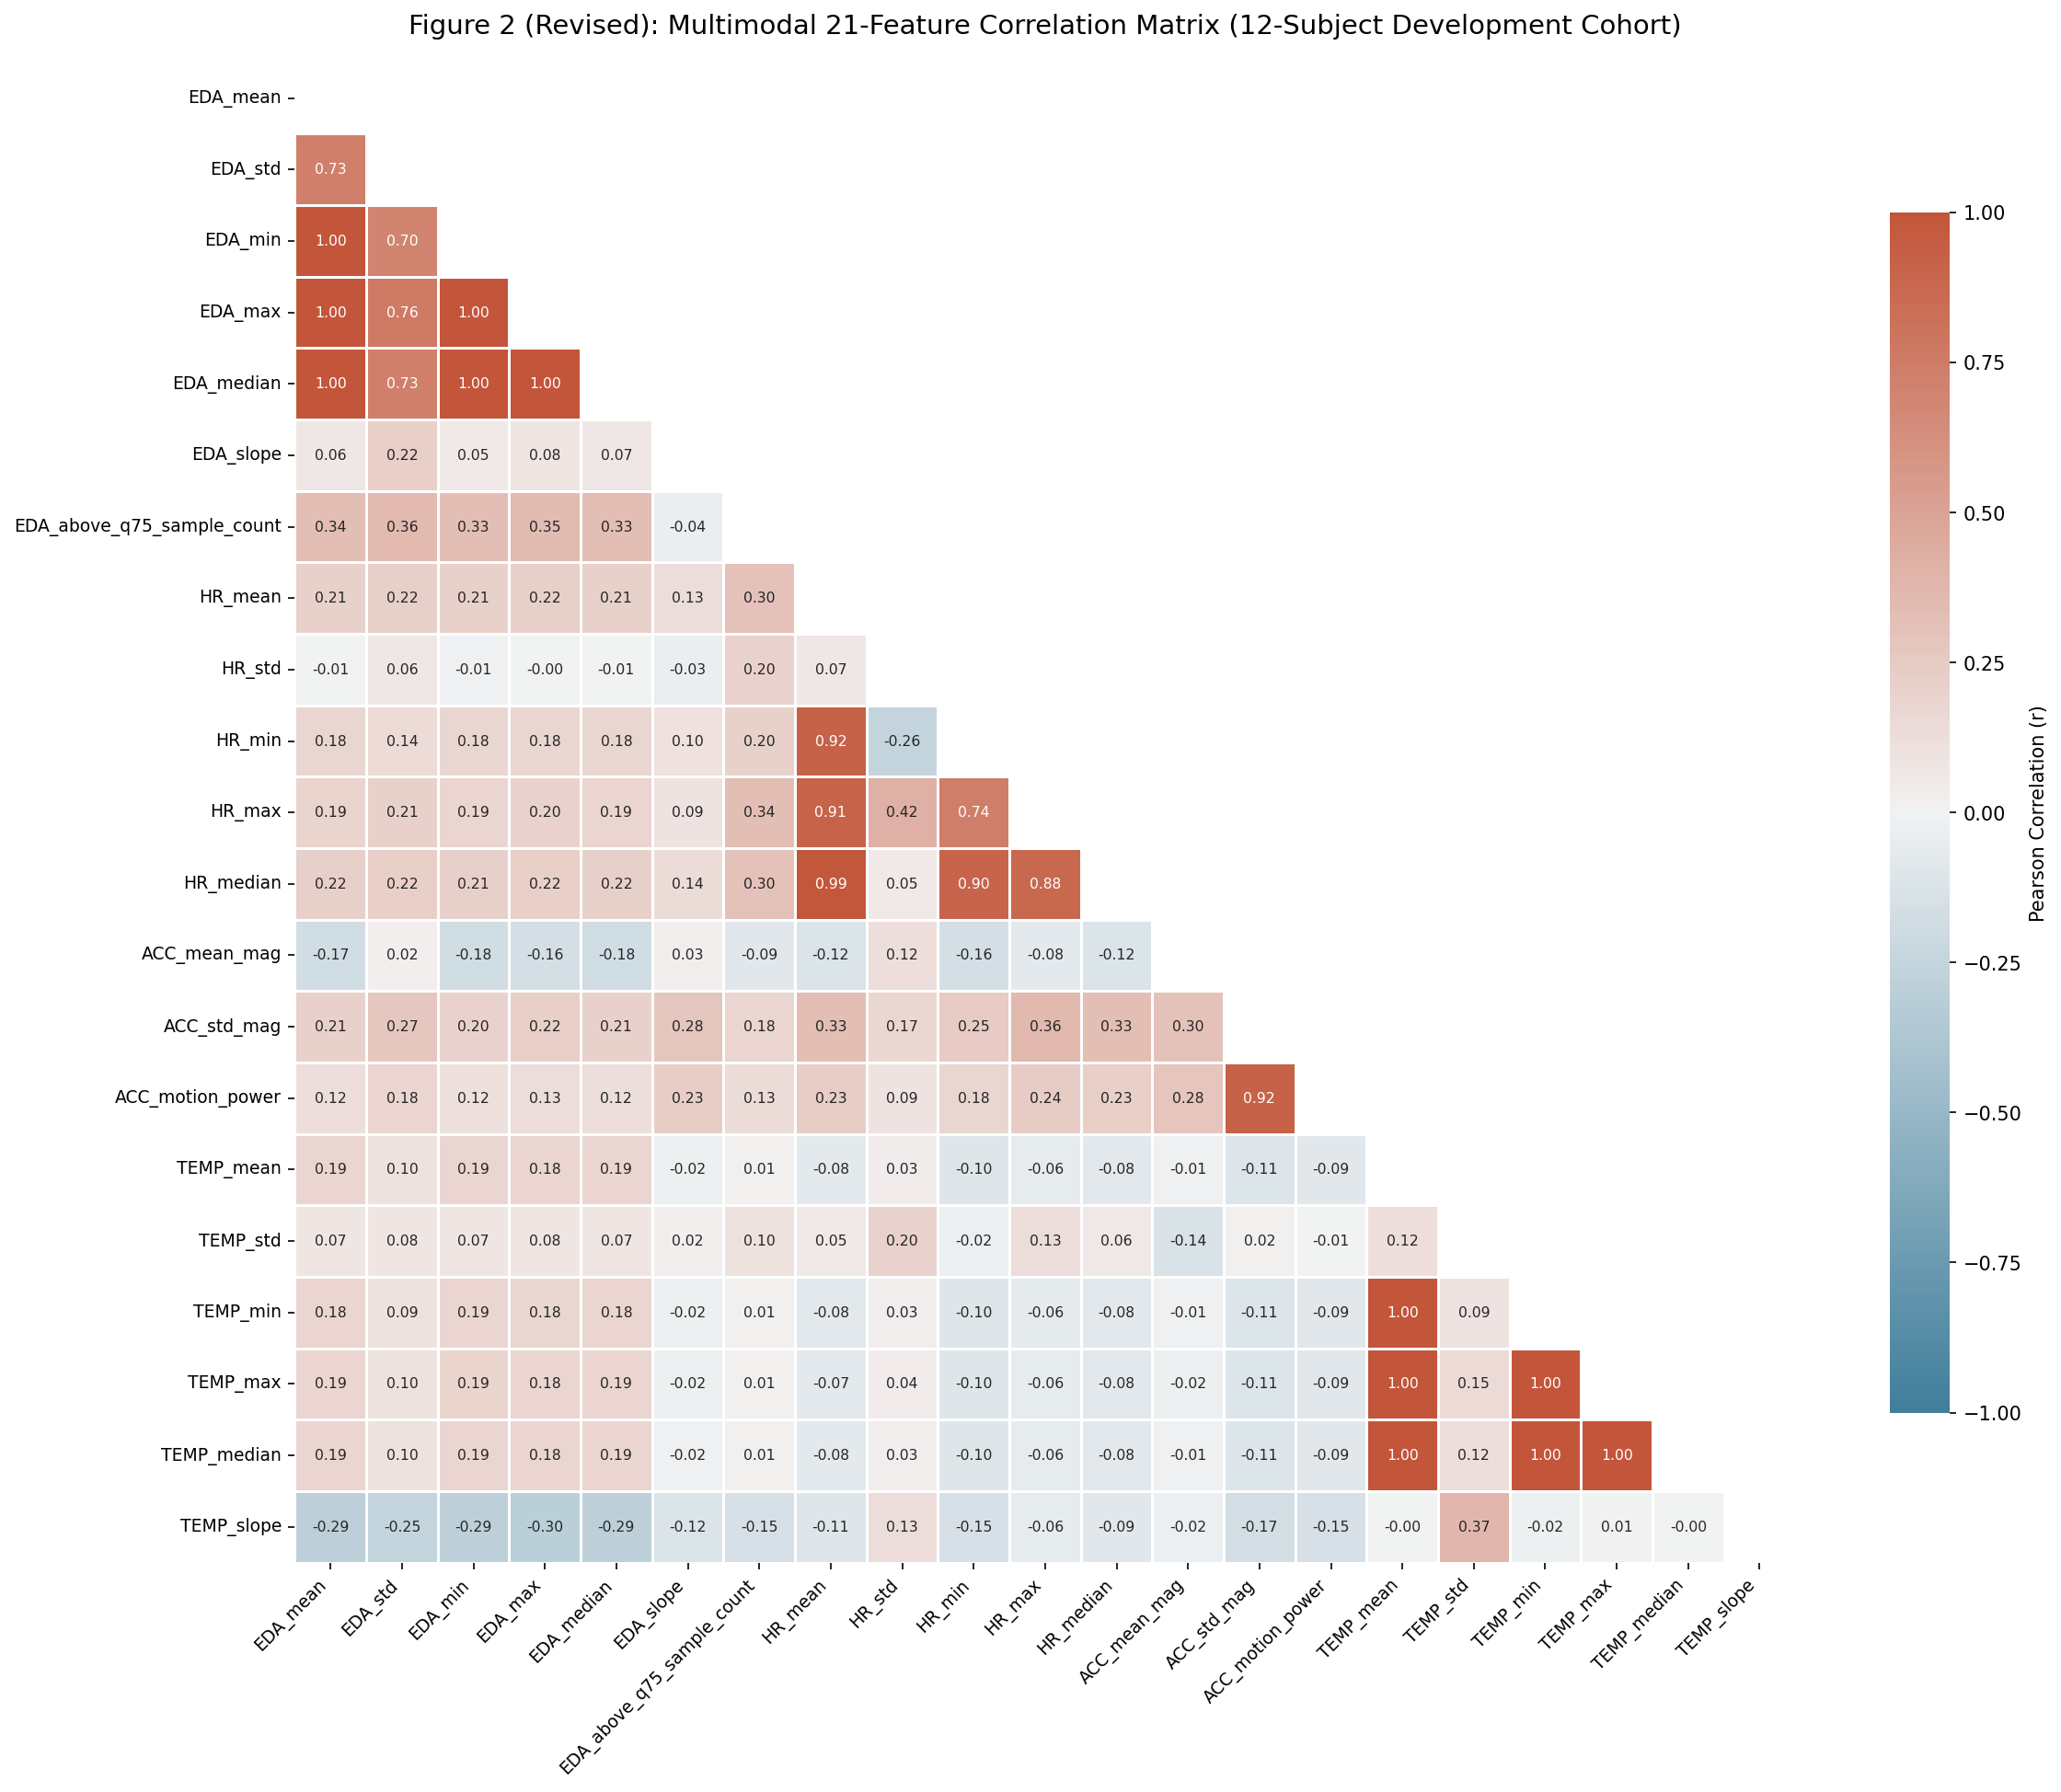

Identified 17 feature pairs with |r| >= 0.90 in Development Cohort.

Normalization Sensitivity (4-Fold GroupKFold on 12/12 Dual-Class Dev Subjects):
  Inductive Cohort Training-Fold StandardScaler : F1 = 0.8368 | AUC = 0.9498
  Offline Transductive Per-Subject Z-Scoring    : F1 = 0.8925 | AUC = 0.9795 [Requires Full-Session Test Access]


In [4]:
corr_matrix = dev_df[feature_cols].corr()

plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, mask=mask, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"},
    annot=True, fmt=".2f", annot_kws={"size": 7.5}
)
plt.title("Figure 2 (Revised): Multimodal 21-Feature Correlation Matrix (12-Subject Development Cohort)", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig("figure2_feature_correlation_revised.png", dpi=300, bbox_inches='tight')
plt.show()

high_corr = [
    (corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j])
    for i in range(len(corr_matrix.columns)) for j in range(i + 1, len(corr_matrix.columns))
    if abs(corr_matrix.iloc[i, j]) >= 0.90
]
print(f"Identified {len(high_corr)} feature pairs with |r| >= 0.90 in Development Cohort.")

# Inductive Cohort StandardScaler vs. Offline Transductive Per-Subject Z-Scoring
gkf_dev = GroupKFold(n_splits=4)
dual_subjs = [s for s, grp in dev_df.groupby('subject') if grp['target'].nunique() == 2]
sub_df = dev_df[dev_df['subject'].isin(dual_subjs)].copy()
Xs, ys, gs = sub_df[feature_cols].values, sub_df['target'].values, sub_df['subject'].values

# Transductive: uses full-session mean & std per subject (non-causal benchmark only)
Xs_subj_transductive = sub_df.groupby('subject')[feature_cols].transform(
    lambda g: (g - g.mean()) / (g.std(ddof=0) + 1e-8)
).values

f1_glob, f1_subj, auc_glob, auc_subj = [], [], [], []
for tr, va in gkf_dev.split(Xs, ys, groups=gs):
    sg = StandardScaler()
    c1 = make_classifier('LR', True).fit(sg.fit_transform(Xs[tr]), ys[tr])
    f1_glob.append(f1_score(ys[va], c1.predict(sg.transform(Xs[va])), zero_division=0))
    auc_glob.append(roc_auc_score(ys[va], c1.predict_proba(sg.transform(Xs[va]))[:, 1]))

    c2 = make_classifier('LR', True).fit(Xs_subj_transductive[tr], ys[tr])
    f1_subj.append(f1_score(ys[va], c2.predict(Xs_subj_transductive[va]), zero_division=0))
    auc_subj.append(roc_auc_score(ys[va], c2.predict_proba(Xs_subj_transductive[va])[:, 1]))

print(f"\nNormalization Sensitivity (4-Fold GroupKFold on {len(dual_subjs)}/12 Dual-Class Dev Subjects):")
print(f"  Inductive Cohort Training-Fold StandardScaler : F1 = {np.mean(f1_glob):.4f} | AUC = {np.mean(auc_glob):.4f}")
print(f"  Offline Transductive Per-Subject Z-Scoring    : F1 = {np.mean(f1_subj):.4f} | AUC = {np.mean(auc_subj):.4f} [Requires Full-Session Test Access]")

---
## 4. Collinearity-Pruned Feature-Reduction Experiment (Development Cohort CV)
Compares the full **21 multimodal features** against:
1. **Collinearity-Pruned 12 Features** (dropping static extrema `min`, `max`, `median`; leaves one variance-vs-SD pair `ACC_std_mag` vs. `ACC_motion_power`, `r = 0.9208`), and
2. **Collinearity-Pruned 11 Features (Zero `|r| >= 0.90`)** (additionally removing `ACC_motion_power = ACC_std_mag^2` so zero collinear pairs with `|r| >= 0.90` remain).
Evaluated via 4-fold `GroupKFold` strictly inside the 12-subject Development Cohort.

In [5]:
pruned_11_features = [
    'EDA_mean', 'EDA_std', 'EDA_slope', 'EDA_above_q75_sample_count',
    'HR_mean', 'HR_std', 'ACC_mean_mag', 'ACC_std_mag',
    'TEMP_mean', 'TEMP_std', 'TEMP_slope'
]
pruned_12_features = pruned_11_features[:8] + ['ACC_motion_power'] + pruned_11_features[8:]

prune_rows = []
for label_set, cols in [
    ("Full 21 Features", feature_cols),
    ("Collinearity-Pruned 12 Features", pruned_12_features),
    ("Collinearity-Pruned 11 Features (Zero |r|>=0.90)", pruned_11_features)
]:
    X_f, X_ex_f = dev_df[cols].values, exam_raw[cols].values
    t_f1s, t_accs, t_aucs, s_f1s, s_accs, s_aucs = [], [], [], [], [], []
    for tr_idx, va_idx in gkf_dev.split(X_f, y_dev, groups=g_dev):
        sc = StandardScaler()
        X_tr_sc, X_va_sc, X_ex_sc = sc.fit_transform(X_f[tr_idx]), sc.transform(X_f[va_idx]), sc.transform(X_ex_f)
        th = calibrate_teacher_oof(lambda: make_classifier('LR', True), X_f[tr_idx], y_dev[tr_idx], g_dev[tr_idx], n_splits=3)

        t_clf = make_classifier('LR', True).fit(X_tr_sc, y_dev[tr_idx])
        tp, tpr = t_clf.predict(X_va_sc), t_clf.predict_proba(X_va_sc)[:, 1]
        t_f1s.append(f1_score(y_dev[va_idx], tp, zero_division=0)); t_accs.append(accuracy_score(y_dev[va_idx], tp))
        t_aucs.append(roc_auc_score(y_dev[va_idx], tpr))

        st = run_iterative_self_training(X_tr_sc, y_dev[tr_idx], X_ex_sc, th)
        s_clf = make_classifier('LR', True).fit(st['X_aug'], st['y_aug'])
        sp, spr = s_clf.predict(X_va_sc), s_clf.predict_proba(X_va_sc)[:, 1]
        s_f1s.append(f1_score(y_dev[va_idx], sp, zero_division=0)); s_accs.append(accuracy_score(y_dev[va_idx], sp))
        s_aucs.append(roc_auc_score(y_dev[va_idx], spr))

    prune_rows.append({"Feature Set": label_set, "Model": "Pure WESAD Teacher (LR)",
                       "Dev_CV_Acc": round(np.mean(t_accs), 4), "Dev_CV_F1": round(np.mean(t_f1s), 4), "Dev_CV_AUC": round(np.mean(t_aucs), 4)})
    prune_rows.append({"Feature Set": label_set, "Model": "Self-Trained Student (LR)",
                       "Dev_CV_Acc": round(np.mean(s_accs), 4), "Dev_CV_F1": round(np.mean(s_f1s), 4), "Dev_CV_AUC": round(np.mean(s_aucs), 4)})

print("=" * 95)
print("TABLE 2: Collinearity Feature Reduction (4-Fold GroupKFold on 12 Dev Subjects)")
print("=" * 95)
print(pd.DataFrame(prune_rows).to_string(index=False))
print("=" * 95)

TABLE 2: Collinearity Feature Reduction (4-Fold GroupKFold on 12 Dev Subjects)
                                     Feature Set                     Model  Dev_CV_Acc  Dev_CV_F1  Dev_CV_AUC
                                Full 21 Features   Pure WESAD Teacher (LR)      0.8564     0.8368      0.9498
                                Full 21 Features Self-Trained Student (LR)      0.8479     0.8209      0.9485
                 Collinearity-Pruned 12 Features   Pure WESAD Teacher (LR)      0.8648     0.8441      0.9570
                 Collinearity-Pruned 12 Features Self-Trained Student (LR)      0.8928     0.8571      0.9618
Collinearity-Pruned 11 Features (Zero |r|>=0.90)   Pure WESAD Teacher (LR)      0.8480     0.8252      0.9470
Collinearity-Pruned 11 Features (Zero |r|>=0.90) Self-Trained Student (LR)      0.8732     0.8330      0.9534


---
## 5. Sensor Modality Ablation Study (Clean Uncontaminated 21-Feature Partition)
Quantifies single-modality and leave-one-modality-out contributions strictly inside the 12-subject Development Cohort (`4-Fold GroupKFold`) after removing cross-modality ACC-into-EDA contamination: `EDA (7)`, `HR (5)`, `ACC (3)`, and `TEMP (6)`.

TABLE 3: Modality Ablation (4-Fold GroupKFold on 12 Development Subjects, Clean 21 Features)
             Subset  Teacher_CV_F1  Student_CV_F1  Student_CV_Acc  Student_CV_AUC
All Modalities (21)         0.8368         0.8209          0.8479          0.9485
       EDA Only (7)         0.7027         0.6474          0.7089          0.8381
        HR Only (5)         0.7482         0.7430          0.8194          0.8824
       ACC Only (3)         0.4795         0.4217          0.7006          0.6724
      TEMP Only (6)         0.6739         0.3613          0.6639          0.7754
   Without EDA (14)         0.7893         0.7527          0.8080          0.9177
    Without HR (16)         0.7340         0.6688          0.7883          0.8476
   Without ACC (18)         0.8360         0.8244          0.8590          0.9394
  Without TEMP (15)         0.8248         0.7925          0.8338          0.9172


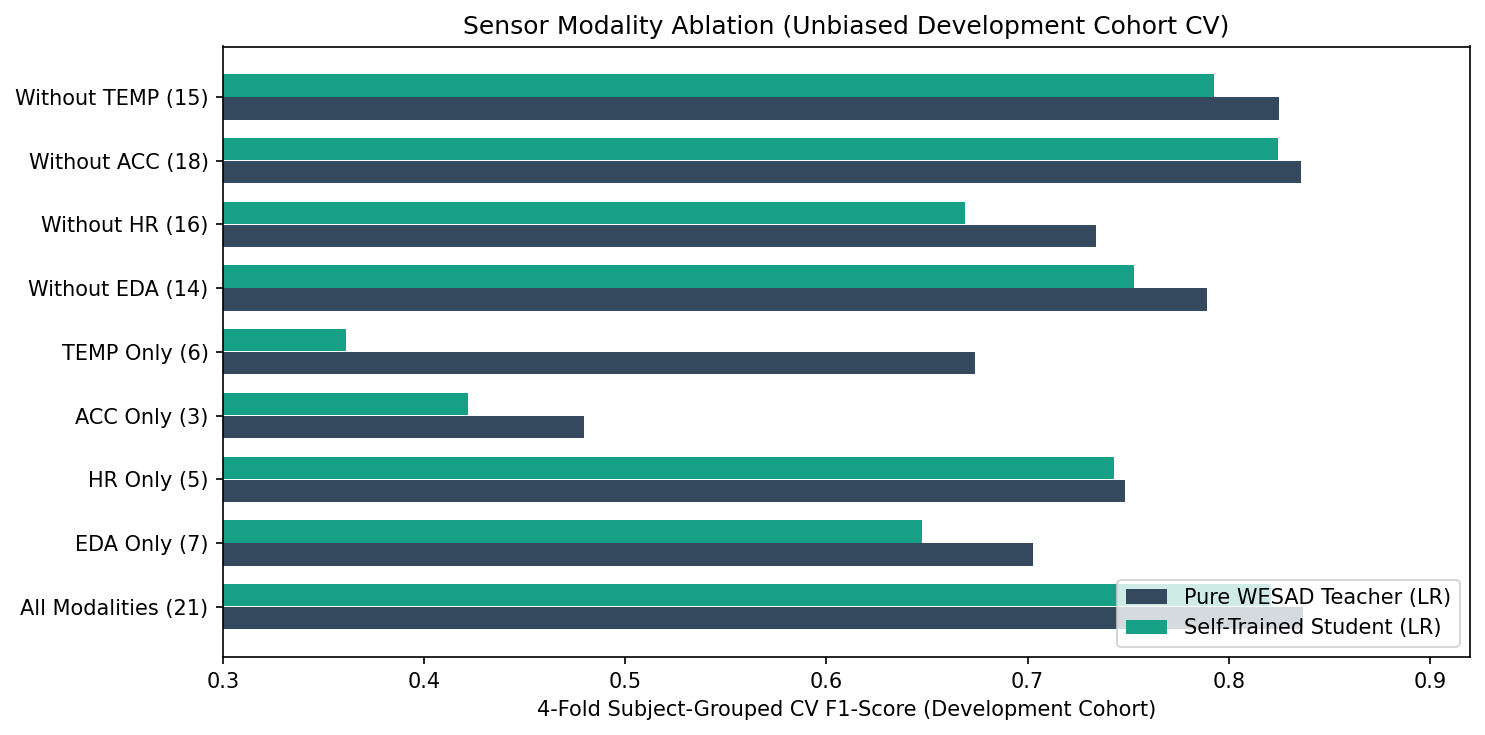

In [6]:
modality_subsets = {
    'All Modalities (21)': feature_cols,
    'EDA Only (7)': [c for c in feature_cols if c.startswith('EDA_')],
    'HR Only (5)': [c for c in feature_cols if c.startswith('HR_')],
    'ACC Only (3)': [c for c in feature_cols if c.startswith('ACC_')],
    'TEMP Only (6)': [c for c in feature_cols if c.startswith('TEMP_')],
    'Without EDA (14)': [c for c in feature_cols if not c.startswith('EDA_')],
    'Without HR (16)': [c for c in feature_cols if not c.startswith('HR_')],
    'Without ACC (18)': [c for c in feature_cols if not c.startswith('ACC_')],
    'Without TEMP (15)': [c for c in feature_cols if not c.startswith('TEMP_')],
}

abl_rows = []
for m_label, cols in modality_subsets.items():
    X_m, X_ex_m = dev_df[cols].values, exam_raw[cols].values
    t_f1, s_f1, s_acc, s_auc = [], [], [], []
    for tr_idx, va_idx in gkf_dev.split(X_m, y_dev, groups=g_dev):
        sc = StandardScaler()
        X_tr_sc, X_va_sc, X_ex_sc = sc.fit_transform(X_m[tr_idx]), sc.transform(X_m[va_idx]), sc.transform(X_ex_m)
        th = calibrate_teacher_oof(lambda: make_classifier('LR', True), X_m[tr_idx], y_dev[tr_idx], g_dev[tr_idx], n_splits=3)

        t_clf = make_classifier('LR', True).fit(X_tr_sc, y_dev[tr_idx])
        t_f1.append(f1_score(y_dev[va_idx], t_clf.predict(X_va_sc), zero_division=0))

        st = run_iterative_self_training(X_tr_sc, y_dev[tr_idx], X_ex_sc, th)
        s_clf = make_classifier('LR', True).fit(st['X_aug'], st['y_aug'])
        sp, spr = s_clf.predict(X_va_sc), s_clf.predict_proba(X_va_sc)[:, 1]
        s_f1.append(f1_score(y_dev[va_idx], sp, zero_division=0))
        s_acc.append(accuracy_score(y_dev[va_idx], sp))
        s_auc.append(roc_auc_score(y_dev[va_idx], spr))

    abl_rows.append({
        'Subset': m_label, 'Teacher_CV_F1': round(np.mean(t_f1), 4),
        'Student_CV_F1': round(np.mean(s_f1), 4), 'Student_CV_Acc': round(np.mean(s_acc), 4),
        'Student_CV_AUC': round(np.mean(s_auc), 4)
    })

df_ablation = pd.DataFrame(abl_rows)
print("=" * 85)
print("TABLE 3: Modality Ablation (4-Fold GroupKFold on 12 Development Subjects, Clean 21 Features)")
print("=" * 85)
print(df_ablation.to_string(index=False))

plt.figure(figsize=(10, 5))
y_pos = np.arange(len(df_ablation))
plt.barh(y_pos - 0.18, df_ablation['Teacher_CV_F1'], height=0.35, color='#34495e', label='Pure WESAD Teacher (LR)')
plt.barh(y_pos + 0.18, df_ablation['Student_CV_F1'], height=0.35, color='#16a085', label='Self-Trained Student (LR)')
plt.yticks(y_pos, df_ablation['Subset'])
plt.xlabel("4-Fold Subject-Grouped CV F1-Score (Development Cohort)")
plt.title("Sensor Modality Ablation (Unbiased Development Cohort CV)", fontsize=12)
plt.xlim(0.30, 0.92)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("figure_modality_ablation.png", dpi=300, bbox_inches='tight')
plt.show()

---
## 6. Independent Calibration-Validation, Selective Self-Training, & Exam Time-Phase Audit
- **Nested Grouped Calibration-Validation ([Critical 3 Fix])**: Thresholds selected via inner `GroupKFold` (`cal_train`) are evaluated on completely held-out `cal_val` subjects across `LR`, `RF`, and `SVC`, reporting **Selection Precision** vs. **Independent Cal-Val Precision** alongside **Wilson 95% CIs**, **Cluster Bootstrap 95% CIs**, and **Accepted Coverage**.
- **Policy Justification (`{0: 0.95, 1: 0.75}, min_tau = 0.80`)**: Under unfloored `{0: 0.90, 1: 0.75}, min_tau = 0.50`, `LR` Non-Stress threshold sits near the coin-flip boundary (`Mean_Tau = 0.5324`) and `SVC` defaults to `(0.5646, 0.5780)` with only `8.2%` Dev abstention. Enforcing `{0: 0.95, 1: 0.75}` with `min_tau = 0.80` enforces genuine high-confidence gating across all three teachers (`LR Mean_Tau = 0.8362 / 0.9317`, `0.9653` / `0.7711` unseen Cal-Val precision with `27.7%` Dev abstention; Dev 4-fold OOF `tau_0 = 0.809, tau_1 = 0.809`) and abstains **`319`** ambiguous exam windows (`7,051` pseudo-labeled -> `7,405` augmented samples).
- **Protocol Timing & Nominal Exam Audit ([Critical 4 Fix])**: Segments `Midterm 1` & `Midterm 2` into **Pre-Exam (`<09:00 CT`)**, **Nominal Seated Exam (`09:00–10:30 CT`)**, and **Post-Exam (`>=10:30 CT`)** against `Final` (`>=10:28 CST` header offset), proving that sky-high Pre/Post-Exam walking `HR` (`113.3–128.4 bpm`) and cool ambient `TEMP` (`25.2 °C`) inflate whole-recording flag rates (`78.9%–93.9%`) relative to nominal seated exam windows (`HR = 90.2–92.4 bpm`, `EDA_mean ~ 0.430 uS`, `EDA_above_q75 = 51.55–52.50`, pseudo-stress `34.2%–61.7%`).

INDEPENDENT GROUPED CALIBRATION-VALIDATION BENCHMARK (SELECTION VS. UNSEEN CAL_VAL SUBJECTS)

[LR (CostSensitive) | Targets={0: 0.9, 1: 0.75} | min_tau=0.50]
         Class  Target_Prec  Min_Tau  Mean_Tau Target_Met_Folds  Selection_Prec  Indep_CalVal_Prec    Wilson_95CI ClusterBoot_95CI      Accepted_W  TrueClass_Coverage  Total_Abstain%
Non-Stress (0)         0.90      0.5    0.5324              4/4          0.9322             0.9487 [0.908, 0.972]   [0.883, 1.000] 195/354 (55.1%)              0.8114            19.8
    Stress (1)         0.75      0.5    0.8901              4/4          0.7540             0.7640 [0.666, 0.840]   [0.596, 0.968]  89/354 (25.1%)              0.5397            19.8

[LR (CostSensitive) | Targets={0: 0.95, 1: 0.75} | min_tau=0.50]
         Class  Target_Prec  Min_Tau  Mean_Tau Target_Met_Folds  Selection_Prec  Indep_CalVal_Prec    Wilson_95CI ClusterBoot_95CI      Accepted_W  TrueClass_Coverage  Total_Abstain%
Non-Stress (0)         0.95      0.5    0.73

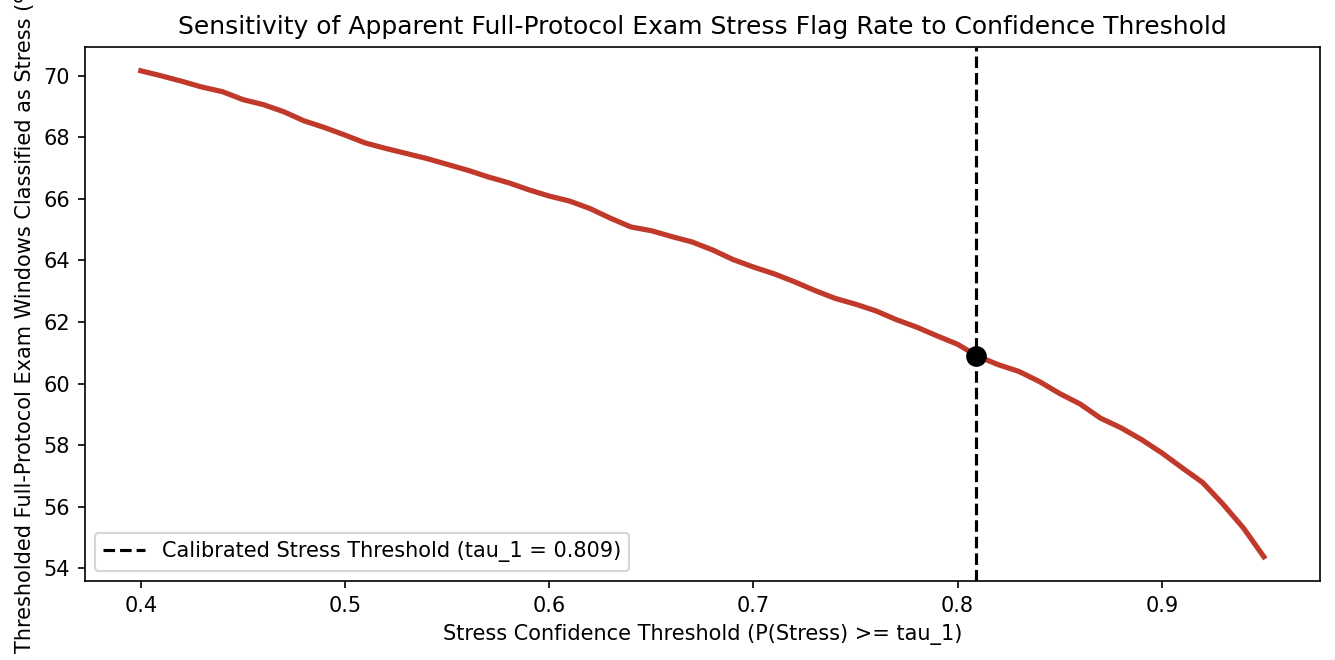

In [7]:
print("=" * 105)
print("INDEPENDENT GROUPED CALIBRATION-VALIDATION BENCHMARK (SELECTION VS. UNSEEN CAL_VAL SUBJECTS)")
print("=" * 105)
for t_name, t_fac in [
    ("LR (CostSensitive)", lambda: make_classifier('LR', True)),
    ("RF (CostSensitive)", lambda: make_classifier('RF', True)),
    ("SVC (CostSensitive)", lambda: make_classifier('SVC', True)),
]:
    for tgt, mtau in [({0: 0.90, 1: 0.75}, 0.50), ({0: 0.95, 1: 0.75}, 0.50), ({0: 0.95, 1: 0.75}, 0.80)]:
        df_cv = validate_calibration_grouped(t_fac, X_dev, y_dev, g_dev, target_prec=tgt, min_tau=mtau)
        print(f"\n[{t_name} | Targets={tgt} | min_tau={mtau:.2f}]")
        print(df_cv.to_string(index=False))

scaler_dev = StandardScaler()
X_dev_sc = scaler_dev.fit_transform(X_dev)
X_exam_sc_dev = scaler_dev.transform(X_exam_raw)

thresholds_lr_dev, calib_diag_dev = calibrate_teacher_oof(
    lambda: make_classifier('LR', True), X_dev, y_dev, g_dev, n_splits=4,
    target_prec={0: 0.95, 1: 0.75}, min_tau=0.80, return_diagnostics=True
)

print("\n" + "=" * 85)
print("SUBJECT-GROUPED OOF CALIBRATION (12 Dev Subjects, LR Teacher; Target={0:0.95, 1:0.75}, min_tau=0.80)")
print("=" * 85)
print(f"  Class 0 (Non-Stress): tau_0 = {thresholds_lr_dev[0]:.3f} | Sel Prec={calib_diag_dev[0]['oof_prec']:.3f}, Sel Rec={calib_diag_dev[0]['oof_rec']:.3f}")
print(f"  Class 1 (Stress)    : tau_1 = {thresholds_lr_dev[1]:.3f} | Sel Prec={calib_diag_dev[1]['oof_prec']:.3f}, Sel Rec={calib_diag_dev[1]['oof_rec']:.3f}")

st_dev = run_iterative_self_training(X_dev_sc, y_dev, X_exam_sc_dev, thresholds_lr_dev, max_iter=5)
X_augmented_dev, y_augmented_dev = st_dev['X_aug'], st_dev['y_aug']

print("\nSelf-Training Iteration Log (Development Cohort + 7,370 Exam Windows):")
print(pd.DataFrame(st_dev['iter_log']).to_string(index=False))
print(f"\nAugmented Matrix: {len(X_augmented_dev)} (WESAD={len(y_dev)}, Pseudo-Labeled={len(X_augmented_dev)-len(y_dev)}, Abstained={st_dev['n_abstained']})")

# Physiological plausibility audit on Exam Pseudo-Label groups
exam_audit = exam_raw.copy()
exam_audit['Pseudo_Group'] = pd.Series(st_dev['exam_assigned']).map({
    0: 'Confident Non-Stress (0)', 1: 'Confident Stress (1)', -1: 'Abstained (Uncertain)'
})
print("\nExam Pseudo-Label Group Counts:")
print(exam_audit['Pseudo_Group'].value_counts().to_string())
print("\nRaw Physiological Means by Exam Pseudo-Label Group (Plausibility vs. Domain Shift):")
print(exam_audit.groupby('Pseudo_Group')[['EDA_mean', 'EDA_above_q75_sample_count', 'HR_mean', 'TEMP_mean', 'ACC_mean_mag', 'ACC_motion_power']].mean().round(3).to_string())

# Nominal Exam vs. Pre/Post-Exam Time-Phase Audit
teacher_sens = make_classifier('LR', True).fit(X_dev_sc, y_dev)
exam_probs_sens = teacher_sens.predict_proba(X_exam_sc_dev)[:, 1]
if EXAM_RAW_DIR.exists():
    df_time = build_exam_window_timestamps(EXAM_RAW_DIR, exam_raw)
    exam_audit['phase'] = df_time['phase']
    exam_audit['teacher_thresh_stress'] = (exam_probs_sens >= thresholds_lr_dev[1])
    exam_audit['is_stress'] = (st_dev['exam_assigned'] == 1)
    exam_audit['is_abstain'] = (st_dev['exam_assigned'] == -1)
    phase_summary = exam_audit.groupby(['exam', 'phase']).agg(
        Windows=('subject', 'count'),
        Teacher_Thresh_Stress_N=('teacher_thresh_stress', 'sum'),
        Teacher_Thresh_Stress_Pct=('teacher_thresh_stress', lambda s: round(s.mean() * 100, 1)),
        Iter_Pseudo_Stress_N=('is_stress', 'sum'),
        Iter_Pseudo_Stress_Pct=('is_stress', lambda s: round(s.mean() * 100, 1)),
        Iter_Abstain_Pct=('is_abstain', lambda s: round(s.mean() * 100, 1)),
        Mean_EDA=('EDA_mean', lambda s: round(s.mean(), 3)),
        Mean_Q75_Cnt=('EDA_above_q75_sample_count', lambda s: round(s.mean(), 2)),
        Mean_HR=('HR_mean', lambda s: round(s.mean(), 1))
    ).reset_index()
    print("\nProtocol Timing Breakdown: Nominal Seated Exam (09:00-10:30 CT) vs. Pre/Post-Exam & Final:")
    print(phase_summary.to_string(index=False))

# Stress prevalence sensitivity curve
thr_grid = np.linspace(0.40, 0.95, 56)
pct_stress = [(exam_probs_sens >= t).mean() * 100 for t in thr_grid]

plt.figure(figsize=(9, 4.5))
plt.plot(thr_grid, pct_stress, color='#c0392b', lw=2.5)
plt.axvline(thresholds_lr_dev[1], color='black', linestyle='--', label=f'Calibrated Stress Threshold (tau_1 = {thresholds_lr_dev[1]:.3f})')
plt.scatter([thresholds_lr_dev[1]], [(exam_probs_sens >= thresholds_lr_dev[1]).mean() * 100], color='black', s=80, zorder=5)
plt.xlabel("Stress Confidence Threshold (P(Stress) >= tau_1)")
plt.ylabel("Thresholded Full-Protocol Exam Windows Classified as Stress (%)")
plt.title("Sensitivity of Apparent Full-Protocol Exam Stress Flag Rate to Confidence Threshold", fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig("figure_stress_prevalence_sensitivity.png", dpi=300, bbox_inches='tight')
plt.show()

---
## 7. Controlled Multi-Teacher Sensitivity Analysis (Independent Calibration & Identical Iterative Loop)
Every teacher architecture (**Logistic Regression**, **Random Forest**, **SVC**) calibrates its own probability thresholds independently via nested 3-fold `GroupKFold` OOF probabilities (`{0: 0.95, 1: 0.75}, min_tau = 0.80`) inside each Development fold and executes the **exact same 5-round iterative self-training loop (`max_iter=5`)**, alongside Iteration 1 (`Iter1`) single-pass snapshots.

In [8]:
teacher_factories = {
    "LogisticRegression": lambda: make_classifier('LR', True),
    "RandomForest": lambda: make_classifier('RF', True),
    "SVC": lambda: make_classifier('SVC', True)
}

mt_rows = []
t_mt = time.time()

for t_name, factory in teacher_factories.items():
    t_f1s, it_lr_f1s, it_rf_f1s, sp_lr_f1s, sp_rf_f1s = [], [], [], [], []
    it_abst_pcts, sp_abst_pcts, th0s, th1s = [], [], [], []

    for tr_idx, va_idx in gkf_dev.split(X_dev, y_dev, groups=g_dev):
        sc = StandardScaler()
        X_tr_sc, X_va_sc, X_ex_sc = sc.fit_transform(X_dev[tr_idx]), sc.transform(X_dev[va_idx]), sc.transform(X_exam_raw)

        th = calibrate_teacher_oof(factory, X_dev[tr_idx], y_dev[tr_idx], g_dev[tr_idx], n_splits=3)
        th0s.append(th[0]); th1s.append(th[1])

        teacher = factory().fit(X_tr_sc, y_dev[tr_idx])
        t_f1s.append(f1_score(y_dev[va_idx], teacher.predict(X_va_sc), zero_division=0))

        # Controlled identical max_iter=5 loop for ALL teachers
        st = run_iterative_self_training(X_tr_sc, y_dev[tr_idx], X_ex_sc, th, teacher_factory=factory, max_iter=5)
        it_abst_pcts.append(st['n_abstained'] / len(X_ex_sc) * 100)
        sp_abst_pcts.append(st['sp_abstained'] / len(X_ex_sc) * 100)

        lr_it = make_classifier('LR', True).fit(st['X_aug'], st['y_aug'])
        rf_it = make_classifier('RF', True).fit(st['X_aug'], st['y_aug'])
        it_lr_f1s.append(f1_score(y_dev[va_idx], lr_it.predict(X_va_sc), zero_division=0))
        it_rf_f1s.append(f1_score(y_dev[va_idx], rf_it.predict(X_va_sc), zero_division=0))

        lr_sp = make_classifier('LR', True).fit(st['X_single_pass'], st['y_single_pass'])
        rf_sp = make_classifier('RF', True).fit(st['X_single_pass'], st['y_single_pass'])
        sp_lr_f1s.append(f1_score(y_dev[va_idx], lr_sp.predict(X_va_sc), zero_division=0))
        sp_rf_f1s.append(f1_score(y_dev[va_idx], rf_sp.predict(X_va_sc), zero_division=0))

    mt_rows.append({
        'Teacher': t_name,
        'Indep_Th(0,1)': f"({np.mean(th0s):.2f}, {np.mean(th1s):.2f})",
        'Teacher_CV_F1': round(np.mean(t_f1s), 4),
        'Iter_Abstain%': round(np.mean(it_abst_pcts), 1),
        'Iter_LR_F1': round(np.mean(it_lr_f1s), 4),
        'Iter_RF_F1': round(np.mean(it_rf_f1s), 4),
        'Iter1_Abstain%': round(np.mean(sp_abst_pcts), 1),
        'Iter1_LR_F1': round(np.mean(sp_lr_f1s), 4),
        'Iter1_RF_F1': round(np.mean(sp_rf_f1s), 4),
    })

print("=" * 105)
print(f"TABLE 4: Controlled Multi-Teacher Sensitivity (4-Fold Dev GroupKFold) [{time.time()-t_mt:.1f}s]")
print("=" * 105)
print(pd.DataFrame(mt_rows).to_string(index=False))

TABLE 4: Controlled Multi-Teacher Sensitivity (4-Fold Dev GroupKFold) [80.2s]
           Teacher Indep_Th(0,1)  Teacher_CV_F1  Iter_Abstain%  Iter_LR_F1  Iter_RF_F1  Iter1_Abstain%  Iter1_LR_F1  Iter1_RF_F1
LogisticRegression  (0.84, 0.93)         0.8368           10.0      0.8209      0.8498            28.3       0.8318       0.8240
      RandomForest  (0.93, 0.81)         0.7884           22.8      0.7641      0.8132            80.8       0.7993       0.8023
               SVC  (0.83, 0.80)         0.8106            2.2      0.7582      0.8380            61.2       0.8183       0.8539


---
## 8. Unbiased Model Selection & 35-Config Comparison via Inner `GroupKFold` (Figures 6, 7, & 8)
- All `35` student configurations ($7$ resampling schemes $\times$ $5$ classifiers) are evaluated strictly inside the **12-subject Development Cohort (`4-Fold GroupKFold`)** using fold-isolated scaling, OOF calibration (`{0: 0.95, 1: 0.75}, min_tau = 0.80`), iterative self-training, and resampling.
- **Figures 6, 7, and 8** visualize all 35 configurations strictly using **Development Cohort Inner-CV Out-of-Fold (`354` windows)** predictions—never touching the locked outer test subjects (`S2`, `S7`, `S11`).
- Only the single top-ranked configuration (`winner_row`) is frozen for one-time outer holdout evaluation in Section 9A.

TABLE 5: INNER 4-FOLD GROUPKFOLD SELECTION ACROSS 35 CONFIGURATIONS (12 Dev Subjects) [159.4s]
 Rank               Config  CV_Mean_F1  CV_SD_F1  Pooled_OOF_F1  Pooled_OOF_Prec  Pooled_OOF_Rec  Pooled_OOF_Acc  Pooled_OOF_AUC  Pooled_OOF_AUPRC
    1      NearMiss + HGBC      0.8898    0.0573         0.8880           0.8647          0.9127          0.9181          0.9742            0.9602
    2   RandomUnder + HGBC      0.8883    0.0595         0.8872           0.8702          0.9048          0.9181          0.9731            0.9568
    3          None + HGBC      0.8870    0.0700         0.8846           0.8582          0.9127          0.9153          0.9745            0.9575
    4         SMOTE + HGBC      0.8869    0.0657         0.8846           0.8582          0.9127          0.9153          0.9719            0.9552
    5 CostSensitive + HGBC      0.8793    0.0685         0.8769           0.8507          0.9048          0.9096          0.9717            0.9542
    6        ADASYN + H

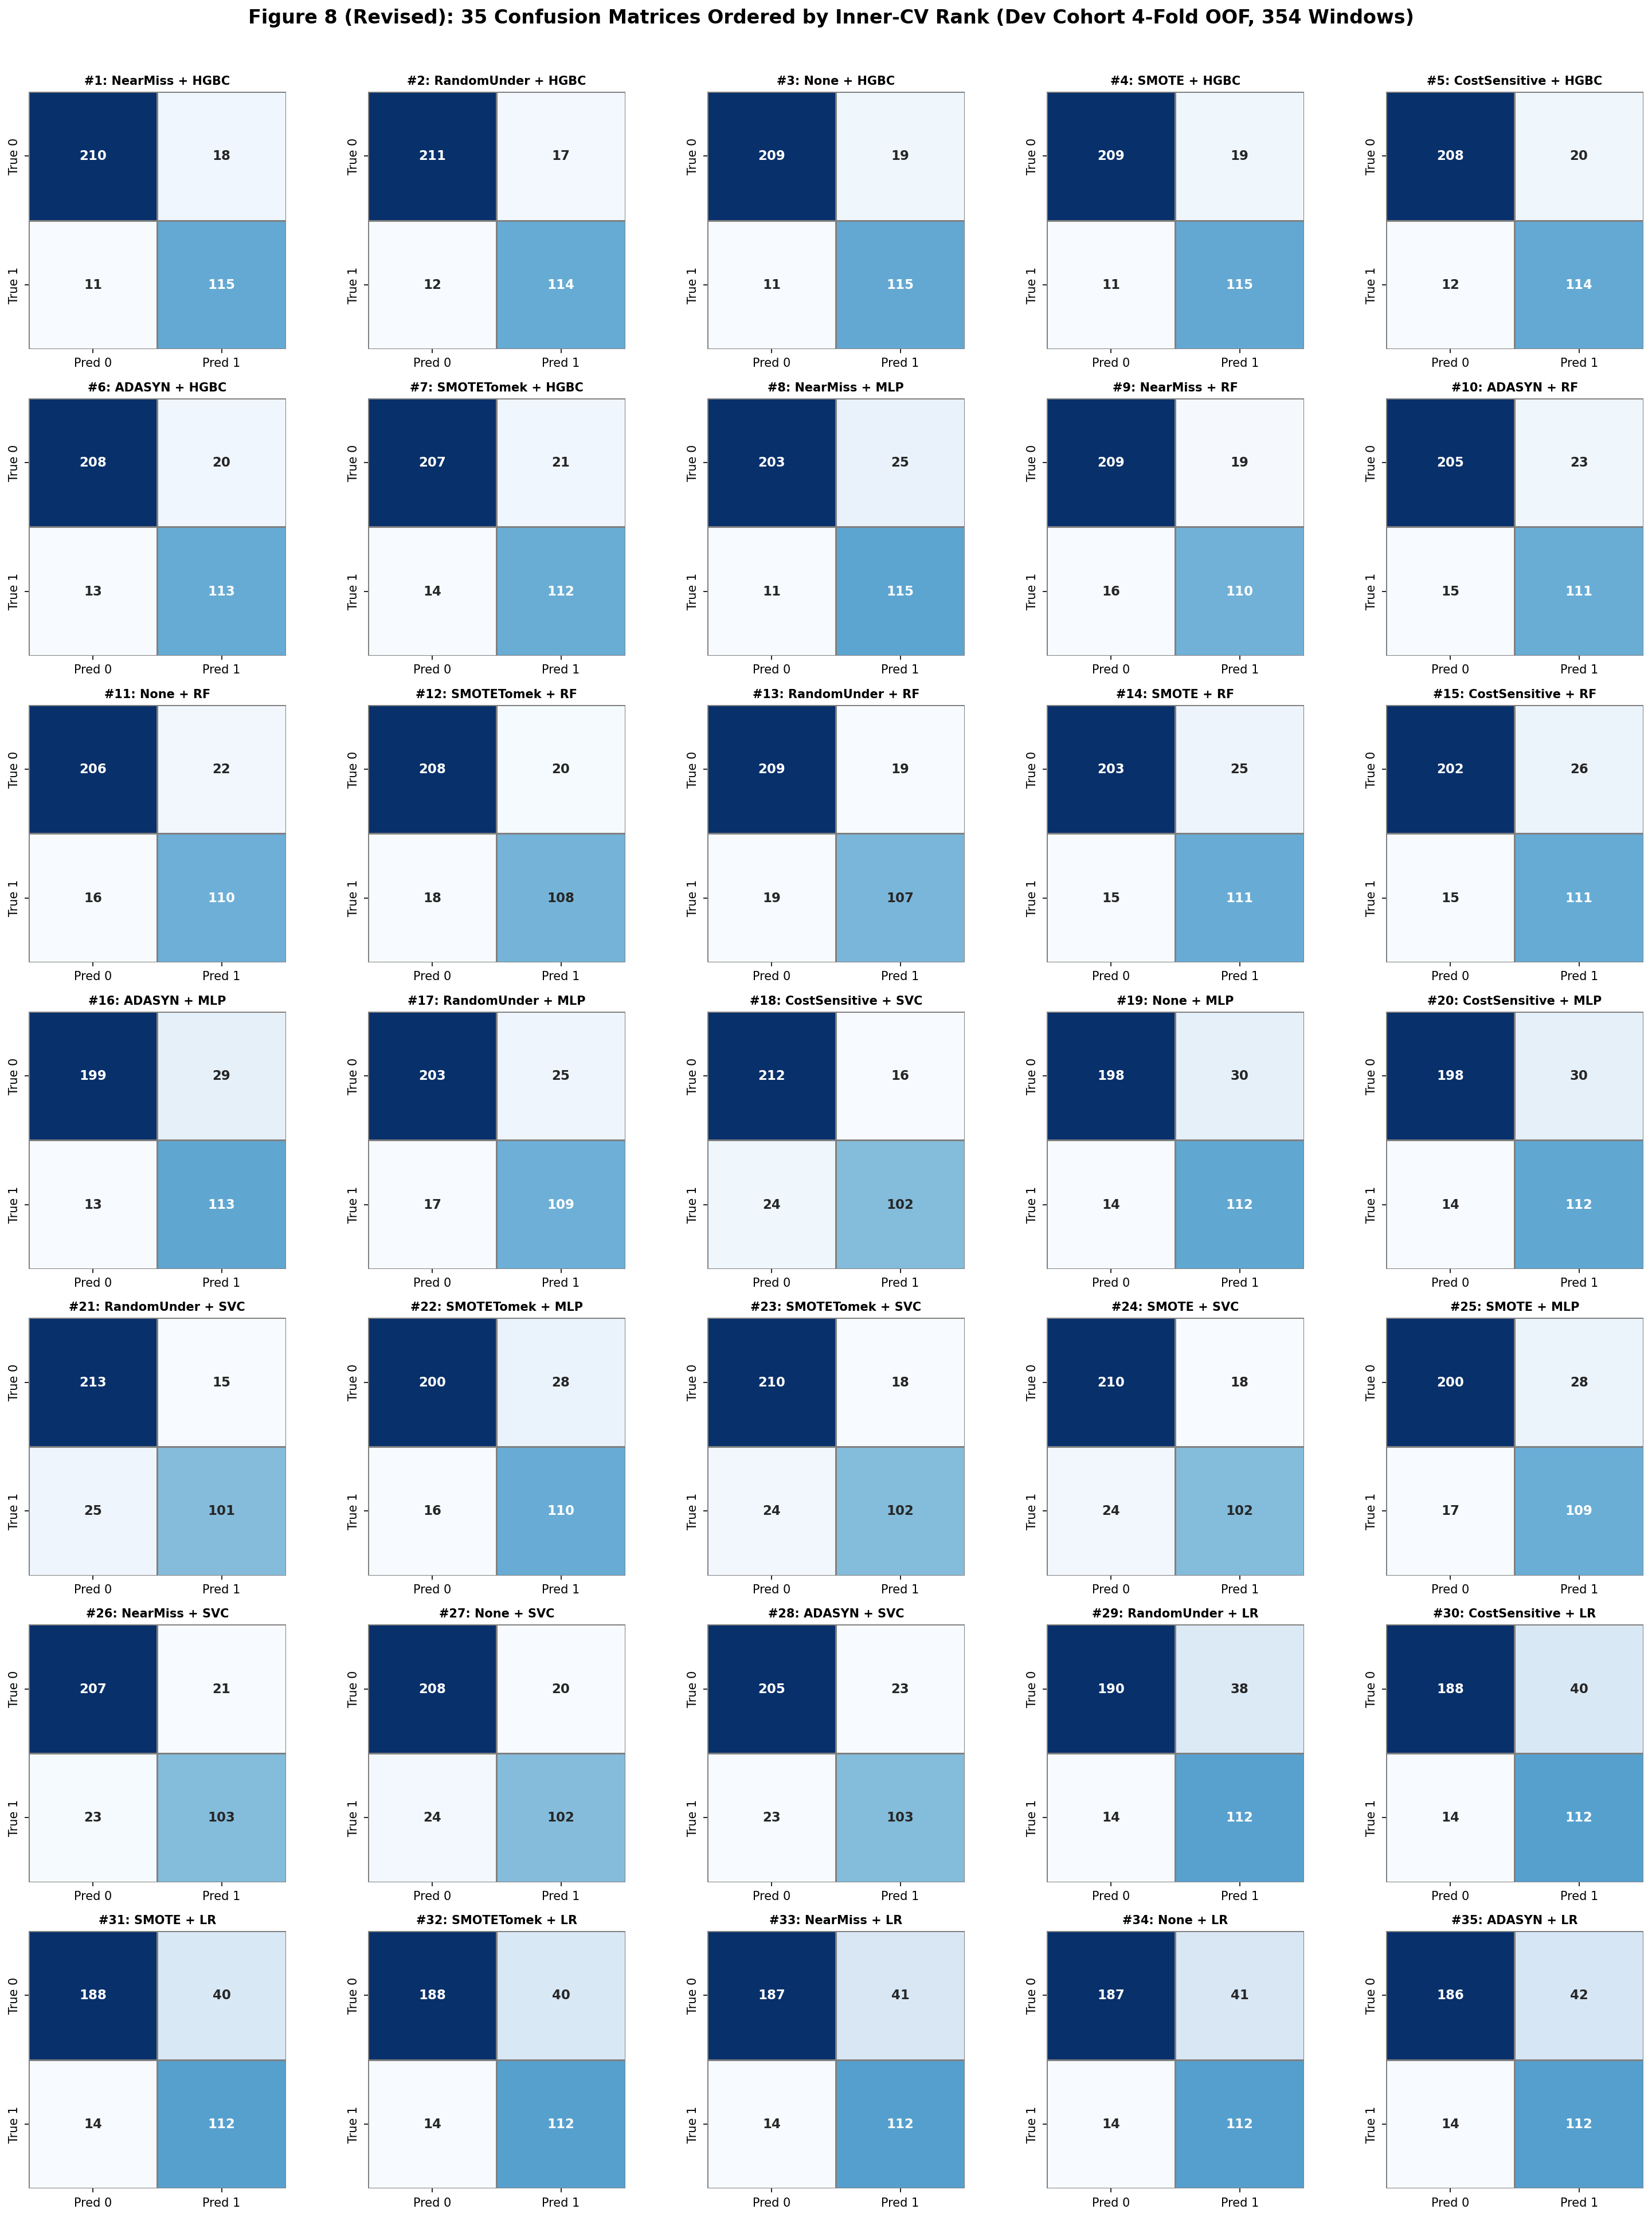

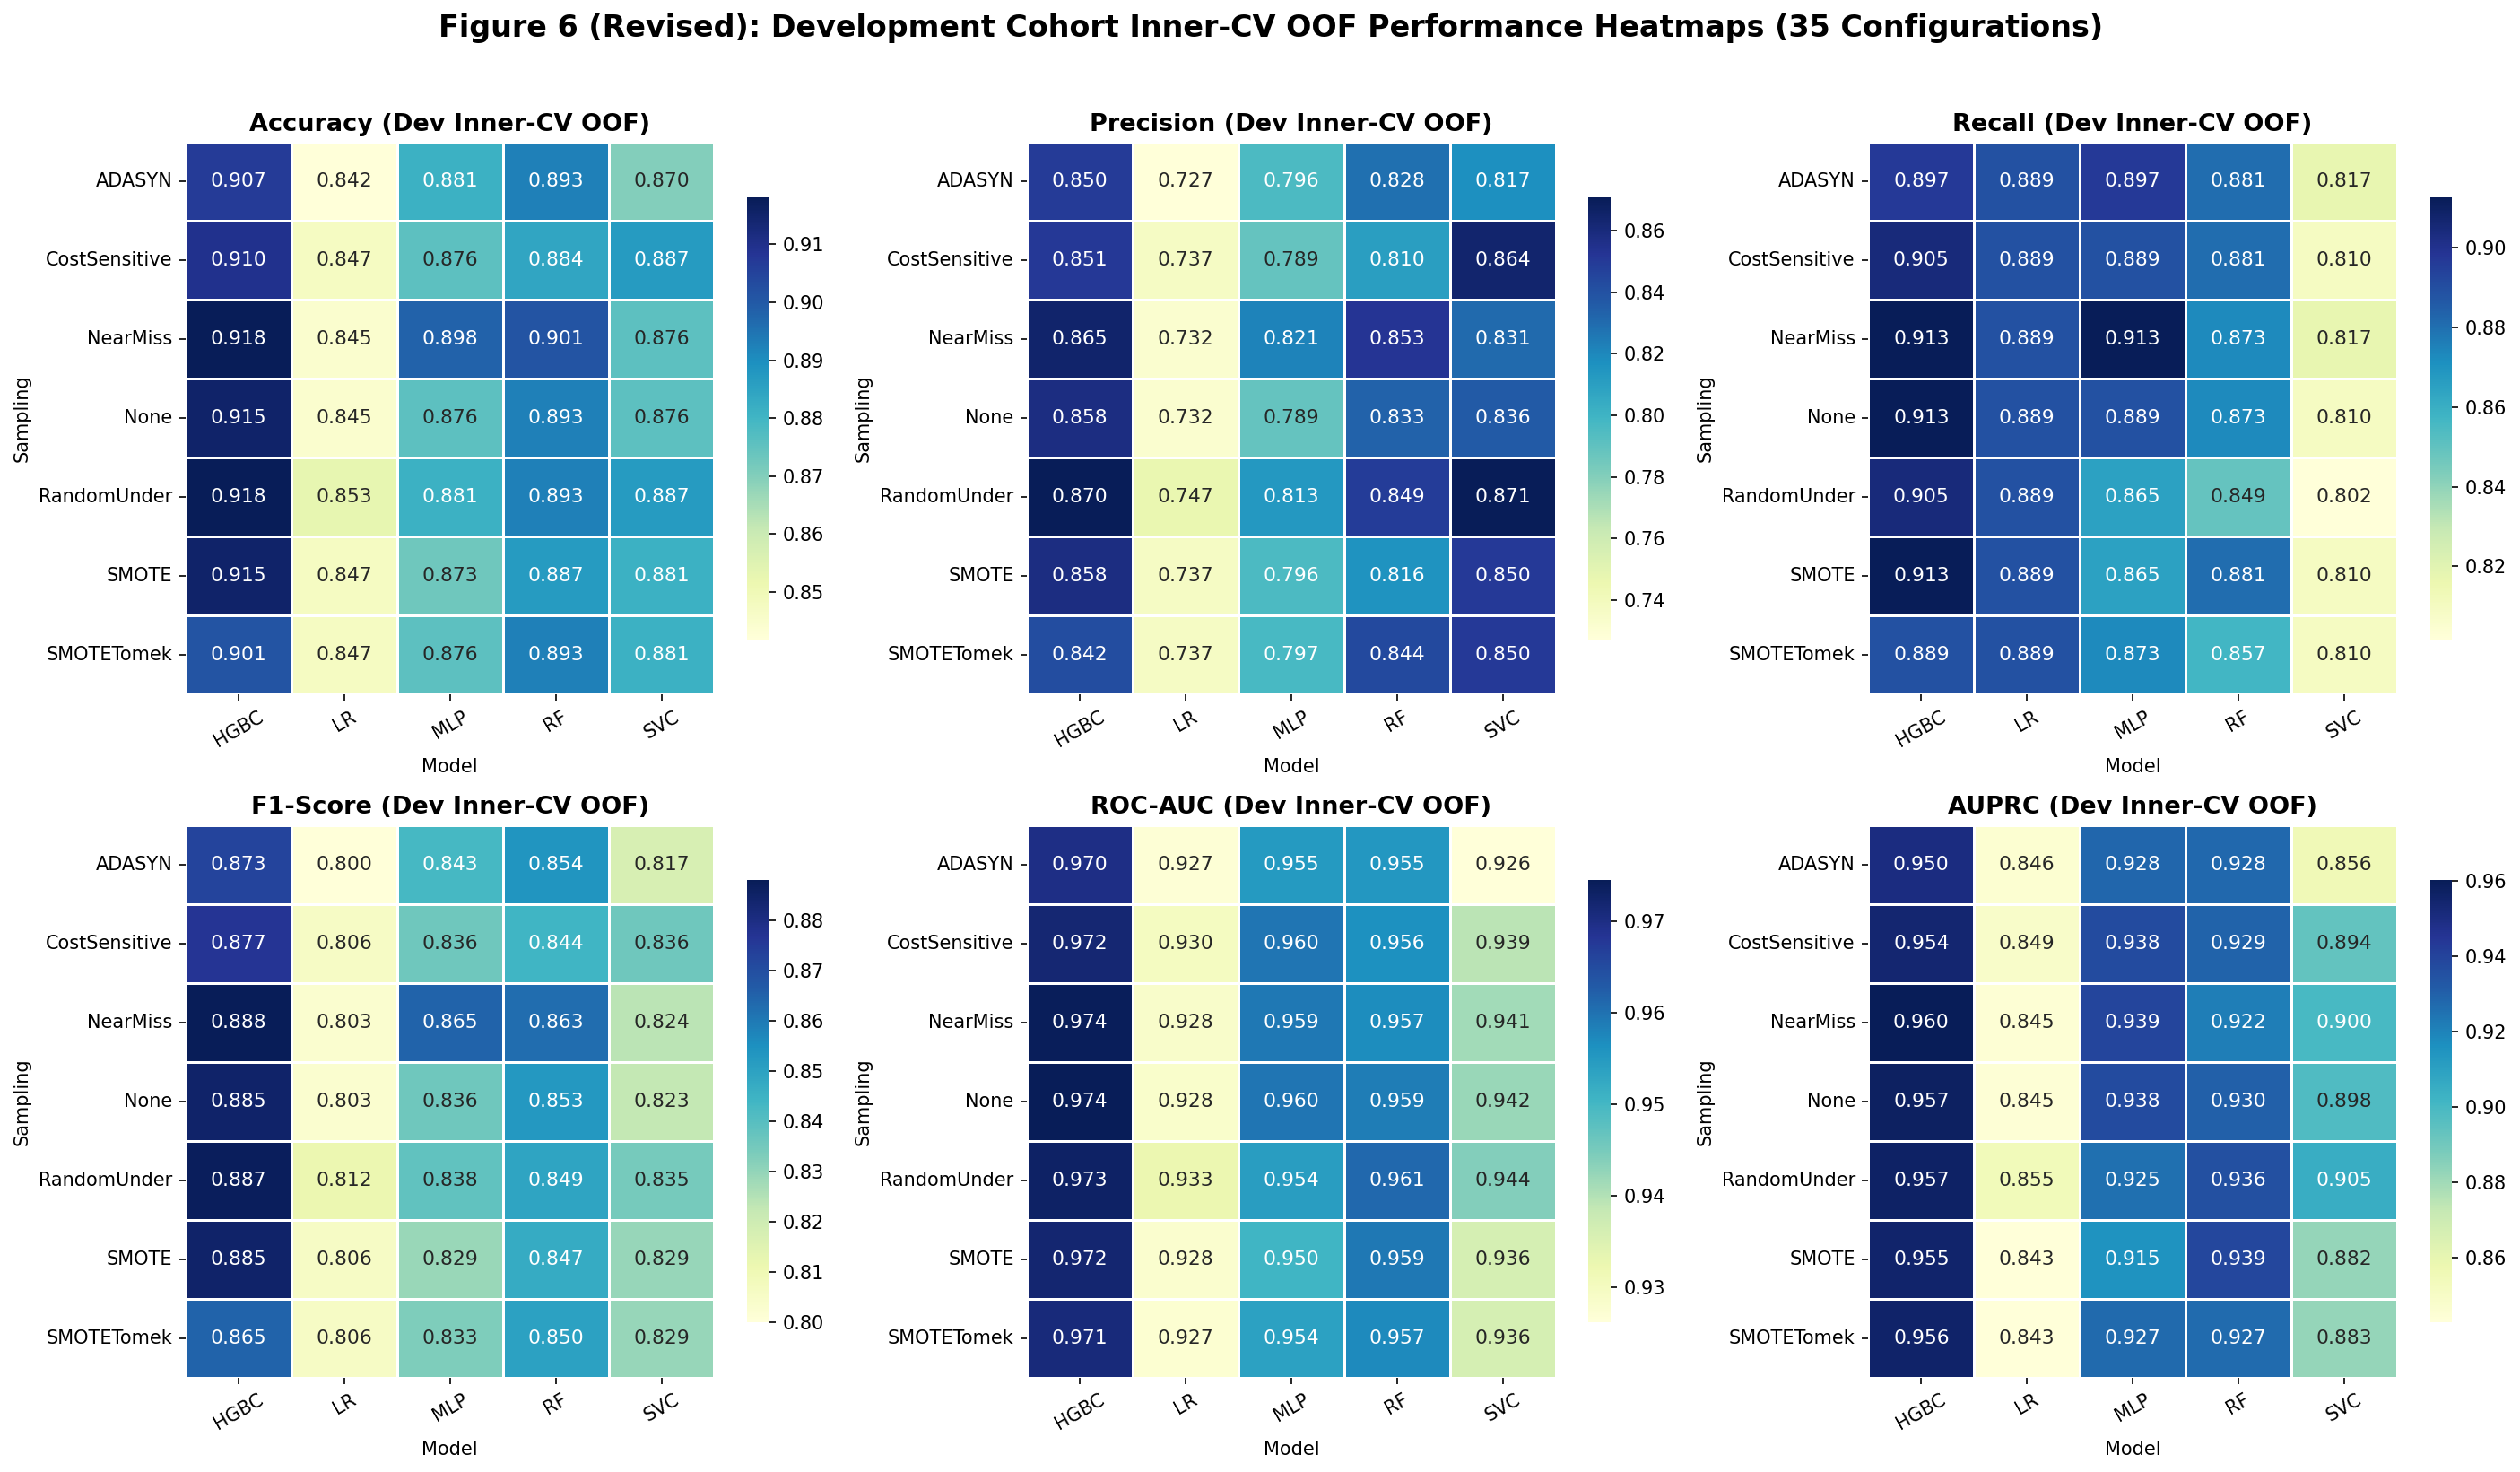

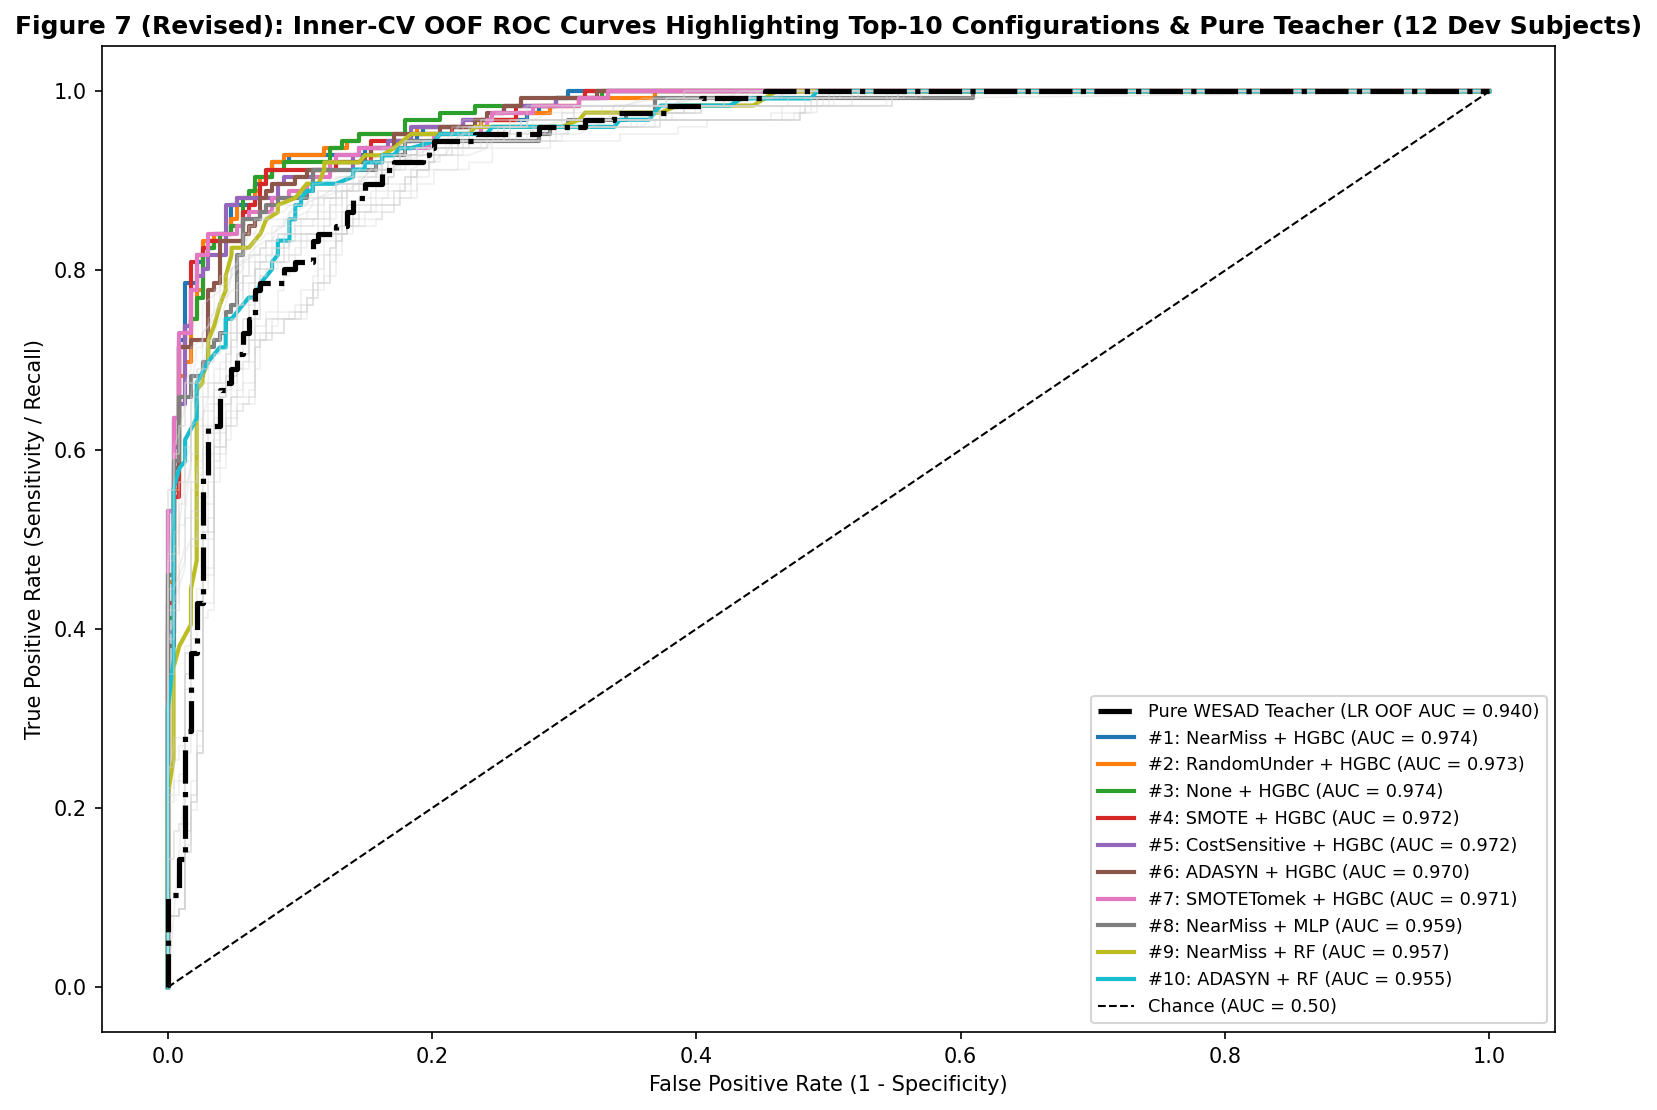

In [9]:
t_in = time.time()
df_inner_ranked, dev_oof_y_true, dev_oof_store, dev_teacher_oof_prob = evaluate_35_configs_grouped_cv(
    X_dev, y_dev, g_dev, X_exam_raw, n_splits=4, calib_splits=3, return_oof=True
)

print("=" * 110)
print(f"TABLE 5: INNER 4-FOLD GROUPKFOLD SELECTION ACROSS 35 CONFIGURATIONS (12 Dev Subjects) [{time.time()-t_in:.1f}s]")
print("=" * 110)
print(df_inner_ranked[['Rank', 'Config', 'CV_Mean_F1', 'CV_SD_F1', 'Pooled_OOF_F1', 'Pooled_OOF_Prec', 'Pooled_OOF_Rec', 'Pooled_OOF_Acc', 'Pooled_OOF_AUC', 'Pooled_OOF_AUPRC']].head(10).round(4).to_string(index=False))

winner_row = df_inner_ranked.iloc[0]
frozen_top10 = df_inner_ranked.head(10)['Config'].tolist()
print(f"\nFrozen Single Winner Selected via Inner CV: {winner_row['Config']} (Mean Inner F1 = {winner_row['CV_Mean_F1']:.4f}, Pooled OOF F1 = {winner_row['Pooled_OOF_F1']:.4f})")

# Figure 8 (Revised): 35 Confusion Matrices from Unbiased Inner-CV Dev OOF (354 windows)
fig, axes = plt.subplots(7, 5, figsize=(20, 26))
axes = axes.flatten()
for idx, row in df_inner_ranked.iterrows():
    ax = axes[idx]
    cm = confusion_matrix(dev_oof_y_true, dev_oof_store[row['Config']]['y_pred'])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, square=True,
        linewidths=1.2, linecolor='gray', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'],
        annot_kws={"size": 11, "weight": "bold"}, ax=ax
    )
    ax.set_title(f"#{int(row['Rank'])}: {row['Config']}", fontsize=10, pad=6, weight='bold')

plt.suptitle('Figure 8 (Revised): 35 Confusion Matrices Ordered by Inner-CV Rank (Dev Cohort 4-Fold OOF, 354 Windows)',
             fontsize=16, y=0.99, weight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("figure8_all_confusion_matrices_grid_revised.png", dpi=300, bbox_inches='tight')
plt.show()

# Figure 6 (Revised): Inner-CV OOF Performance Heatmaps
metrics_to_plot = ['Pooled_OOF_Acc', 'Pooled_OOF_Prec', 'Pooled_OOF_Rec', 'Pooled_OOF_F1', 'Pooled_OOF_AUC', 'Pooled_OOF_AUPRC']
metric_titles = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'AUPRC']
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
axes = axes.flatten()
for i, (m_col, m_title) in enumerate(zip(metrics_to_plot, metric_titles)):
    pivot = df_inner_ranked.pivot_table(values=m_col, index='Sampling', columns='Model')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlGnBu', ax=axes[i],
                linewidths=0.5, cbar_kws={"shrink": 0.8}, annot_kws={"size": 10.5})
    axes[i].set_title(f'{m_title} (Dev Inner-CV OOF)', fontsize=13, weight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle("Figure 6 (Revised): Development Cohort Inner-CV OOF Performance Heatmaps (35 Configurations)", fontsize=16, y=0.99, weight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("figure6_performance_heatmaps_revised.png", dpi=300, bbox_inches='tight')
plt.show()

# Figure 7 (Revised): Inner-CV OOF ROC Curves (Top 10 + Pure Teacher Baseline)
plt.figure(figsize=(10.5, 7.5))
fpr_t, tpr_t, _ = roc_curve(dev_oof_y_true, dev_teacher_oof_prob)
plt.plot(fpr_t, tpr_t, color='black', ls='-.', lw=2.5, label=f"Pure WESAD Teacher (LR OOF AUC = {roc_auc_score(dev_oof_y_true, dev_teacher_oof_prob):.3f})", zorder=10)

for _, row in df_inner_ranked.iterrows():
    cfg = row['Config']
    fpr, tpr, _ = roc_curve(dev_oof_y_true, dev_oof_store[cfg]['y_prob'])
    auc_v = row['Pooled_OOF_AUC']
    if cfg in frozen_top10:
        plt.plot(fpr, tpr, lw=2.0, label=f"#{int(row['Rank'])}: {cfg} (AUC = {auc_v:.3f})")
    else:
        plt.plot(fpr, tpr, color='lightgray', lw=0.8, alpha=0.35)

plt.plot([0, 1], [0, 1], 'k--', lw=1.0, label='Chance (AUC = 0.50)')
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("Figure 7 (Revised): Inner-CV OOF ROC Curves Highlighting Top-10 Configurations & Pure Teacher (12 Dev Subjects)", fontsize=12, weight='bold')
plt.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.savefig("figure7_roc_curves_top10_revised.png", dpi=300, bbox_inches='tight')
plt.show()

---
## 9. Unbiased Outer Evaluation: Single-Winner Holdout Test & Full 15-Subject Nested CV (`5 x 3`)

1. **Part A — Single-Look Locked Outer Holdout Evaluation (`S2`, `S7`, `S11`; $88$ windows)**:
   - Evaluates **strictly ONE frozen Inner-CV winning configuration (`NearMiss + HGBC`)** paired with the **Pure WESAD Teacher baseline (`LR`)**—zero 35-config searching on `test_df`.
   - Explicitly notes that $K=3$ subjects cannot support population inference or cluster bootstrapping (which requires larger subject counts).

2. **Part B — Full 15-Subject True Dynamic Nested Cross-Validation (`5 Outer Folds x 3 Inner Folds`, $442$ windows) & Subject-Level Cluster Bootstrap**:
   - Inside every 12-subject outer training fold (`gkf_outer`), `evaluate_35_configs_grouped_cv(..., n_splits=3)` executes dynamic inner model selection across all `35` configs, trains that fold's winner $c_k^*$ on the fold's self-trained matrix, and tests on the held-out outer fold (alongside `Pure_Teacher_LR` and the interpretable `CostSensitive + LR` linear baseline).
   - Outputs per-fold dynamically chosen models, the complete **Per-Subject Breakdown (`S2`–`S17`, all 15 dual-class!)**, **1,000-Iteration Subject-Level Cluster Bootstrap 95% CIs**, and **WESAD Non-Stress Condition Specificity (`Baseline`, `Stress`, `Amusement`, `Meditation`)**.

In [10]:
# =====================================================================
# PART A: STRICT SINGLE-WINNER EVALUATION ON LOCKED TEST (S2, S7, S11)
# =====================================================================
X_test_sc = scaler_dev.transform(X_test_outer)
samplers_map = dict(SAMPLERS_CFG)

teacher_outer = make_classifier('LR', True).fit(X_dev_sc, y_dev)

s_win, m_win = winner_row['Sampling'], winner_row['Model']
smp_fn_win = samplers_map[s_win]
if smp_fn_win is None or smp_fn_win == 'class_weight':
    X_rw, y_rw = X_augmented_dev, y_augmented_dev
else:
    try:
        X_rw, y_rw = smp_fn_win().fit_resample(X_augmented_dev, y_augmented_dev)
    except ValueError:
        X_rw, y_rw = X_augmented_dev, y_augmented_dev
student_win = make_classifier(m_win, cost_sensitive=(s_win == 'CostSensitive')).fit(X_rw, y_rw)

part_a_rows = []
for lbl, clf_obj in [('Pure WESAD Teacher (LR, No Exam)', teacher_outer),
                     (f"Frozen Inner-CV Winner ({winner_row['Config']})", student_win)]:
    p = clf_obj.predict(X_test_sc)
    pr = clf_obj.predict_proba(X_test_sc)[:, 1]
    part_a_rows.append({
        'Model': lbl,
        'Acc': round(accuracy_score(y_test_outer, p), 4),
        'Prec': round(precision_score(y_test_outer, p, zero_division=0), 4),
        'Rec': round(recall_score(y_test_outer, p, zero_division=0), 4),
        'F1': round(f1_score(y_test_outer, p, zero_division=0), 4),
        'AUC': round(roc_auc_score(y_test_outer, pr), 4),
        'AUPRC': round(average_precision_score(y_test_outer, pr), 4)
    })

print("=" * 105)
print(f"TABLE 6A: SINGLE-LOOK LOCKED OUTER HOLDOUT EVALUATION (S2, S7, S11; {len(y_test_outer)} windows - ZERO SELECTION BIAS)")
print("=" * 105)
print(pd.DataFrame(part_a_rows).to_string(index=False))
print("Note: Only K=3 clusters exist in this holdout; cluster bootstrap inference is computed across all K=15 subjects below.")

# =====================================================================
# PART B: FULL 15-SUBJECT TRUE DYNAMIC NESTED CV (5 OUTER x 3 INNER)
# =====================================================================
t_nest = time.time()
X_all = wesad_binary[feature_cols].values
y_all = wesad_binary['target'].values
g_all = wesad_binary['subject'].values

gkf_outer = GroupKFold(n_splits=5)
nested_preds = {'Nested Dynamic Inner-CV Winner': [], 'Self-Trained Linear (CostSensitive + LR)': [], 'Pure WESAD Teacher (LR)': []}
cond_specificity_preds = {1: [], 2: [], 3: [], 4: []}
fold_winner_log = []

for fold, (tr_idx, te_idx) in enumerate(gkf_outer.split(X_all, y_all, groups=g_all), 1):
    df_fold_in = evaluate_35_configs_grouped_cv(
        X_all[tr_idx], y_all[tr_idx], g_all[tr_idx], X_exam_raw, n_splits=3, calib_splits=3, return_oof=False
    )
    fold_win = df_fold_in.iloc[0]
    s_b, m_b = fold_win['Sampling'], fold_win['Model']
    fold_winner_log.append({
        'Outer_Fold': fold, 'Held_Out_Subjects': list(np.unique(g_all[te_idx])),
        'Selected_Config': f"{s_b} + {m_b}", 'Inner_Pooled_F1': round(fold_win['Pooled_OOF_F1'], 4)
    })

    sc_o = StandardScaler()
    X_tr_sc = sc_o.fit_transform(X_all[tr_idx])
    X_te_sc = sc_o.transform(X_all[te_idx])
    X_ex_sc = sc_o.transform(X_exam_raw)

    th_o = calibrate_teacher_oof(lambda: make_classifier('LR', True), X_all[tr_idx], y_all[tr_idx], g_all[tr_idx], n_splits=4)
    st_o = run_iterative_self_training(X_tr_sc, y_all[tr_idx], X_ex_sc, th_o, max_iter=5)

    smp_o = samplers_map[s_b]
    if smp_o is None or smp_o == 'class_weight':
        Xr_o, yr_o = st_o['X_aug'], st_o['y_aug']
    else:
        try:
            Xr_o, yr_o = smp_o().fit_resample(st_o['X_aug'], st_o['y_aug'])
        except ValueError:
            Xr_o, yr_o = st_o['X_aug'], st_o['y_aug']
    dyn_clf = make_classifier(m_b, cost_sensitive=(s_b == 'CostSensitive')).fit(Xr_o, yr_o)

    lr_clf = make_classifier('LR', True).fit(st_o['X_aug'], st_o['y_aug'])
    t_clf = make_classifier('LR', True).fit(X_tr_sc, y_all[tr_idx])

    for label, clf_obj in [('Nested Dynamic Inner-CV Winner', dyn_clf),
                           ('Self-Trained Linear (CostSensitive + LR)', lr_clf),
                           ('Pure WESAD Teacher (LR)', t_clf)]:
        p = clf_obj.predict(X_te_sc)
        pr = clf_obj.predict_proba(X_te_sc)[:, 1]
        for s, yt, yp, ypr in zip(g_all[te_idx], y_all[te_idx], p, pr):
            nested_preds[label].append({'subject': s, 'y_true': yt, 'y_pred': yp, 'y_prob': ypr})

    held_subjs = np.unique(g_all[te_idx])
    sub_all = wesad_raw[wesad_raw['subject'].isin(held_subjs)]
    for lbl in [1, 2, 3, 4]:
        chunk = sub_all[sub_all['label'] == lbl]
        if len(chunk) > 0:
            cond_specificity_preds[lbl].extend(t_clf.predict(sc_o.transform(chunk[feature_cols].values)).tolist())

print(f"\nCompleted 5x3 True Dynamic Nested CV across all 15 subjects in {time.time()-t_nest:.1f}s")
print("\nPer-Outer-Fold Dynamically Selected Configurations:")
print(pd.DataFrame(fold_winner_log).to_string(index=False))

cluster_rows = []
for label, rows in nested_preds.items():
    st_ci = subject_cluster_bootstrap_ci(pd.DataFrame(rows), n_bootstraps=1000, seed=SEED)
    cluster_rows.append({
        'Strategy': label,
        'Accuracy': f"{st_ci['Acc']:.4f} {st_ci['Acc_95CI']}",
        'Precision': f"{st_ci['Prec']:.4f} {st_ci['Prec_95CI']}",
        'Recall': f"{st_ci['Rec']:.4f} {st_ci['Rec_95CI']}",
        'F1-Score': f"{st_ci['F1']:.4f} {st_ci['F1_95CI']}",
        'ROC-AUC': f"{st_ci['AUC']:.4f} {st_ci['AUC_95CI']}"
    })

print("\n" + "=" * 120)
print(f"TABLE 6B: FULL 15-SUBJECT TRUE NESTED CV ({len(wesad_binary)} WINDOWS) WITH 1,000-ITERATION SUBJECT-LEVEL CLUSTER BOOTSTRAP 95% CIs")
print("=" * 120)
print(pd.DataFrame(cluster_rows).to_string(index=False))

for label in ['Nested Dynamic Inner-CV Winner', 'Self-Trained Linear (CostSensitive + LR)', 'Pure WESAD Teacher (LR)']:
    df_s = pd.DataFrame(nested_preds[label])
    srows = []
    for s, grp in df_s.groupby('subject'):
        yt, yp = grp['y_true'].values, grp['y_pred'].values
        n0, n1 = int((yt == 0).sum()), int((yt == 1).sum())
        srows.append({
            'Subject': s, 'Base(0)': n0, 'Stress(1)': n1, 'Acc': round(accuracy_score(yt, yp), 3),
            'Prec': round(precision_score(yt, yp, zero_division=0), 3) if (yp == 1).sum() > 0 else 'N/A',
            'Rec': round(recall_score(yt, yp, zero_division=0), 3) if n1 > 0 else 'N/A',
            'F1': round(f1_score(yt, yp, zero_division=0), 3) if (n0 > 0 and n1 > 0) else 'N/A'
        })
    print(f"\nSubject-Wise Outer Nested Performance ({label}):")
    print(pd.DataFrame(srows).to_string(index=False))

cond_names = {1: 'Baseline (Non-Stress)', 2: 'TSST Stress', 3: 'Amusement (Pos Arousal)', 4: 'Meditation (Recovery)'}
print("\n" + "=" * 85)
print("TABLE 6C: WESAD Condition-Specific Stress Prediction Rates (15-Subject Outer OOF)")
print("=" * 85)
for lbl in [1, 2, 3, 4]:
    arr = np.array(cond_specificity_preds[lbl])
    print(f"  Label {lbl} ({cond_names[lbl]:<24}): n={len(arr):3d} | Predicted Stress={int(arr.sum()):3d} ({arr.mean()*100:.1f}%)")
print("=" * 85)

TABLE 6A: SINGLE-LOOK LOCKED OUTER HOLDOUT EVALUATION (S2, S7, S11; 88 windows - ZERO SELECTION BIAS)
                                   Model    Acc   Prec    Rec     F1    AUC  AUPRC
        Pure WESAD Teacher (LR, No Exam) 0.8977 0.7750 1.0000 0.8732 0.9825 0.9699
Frozen Inner-CV Winner (NearMiss + HGBC) 0.9432 0.8824 0.9677 0.9231 0.9921 0.9871
Note: Only K=3 clusters exist in this holdout; cluster bootstrap inference is computed across all K=15 subjects below.

Completed 5x3 True Dynamic Nested CV across all 15 subjects in 630.6s

Per-Outer-Fold Dynamically Selected Configurations:
 Outer_Fold Held_Out_Subjects   Selected_Config  Inner_Pooled_F1
          1     [S16, S2, S8]       SMOTE + MLP           0.7723
          2   [S11, S13, S17]    NearMiss + MLP           0.7625
          3     [S10, S3, S6]     NearMiss + RF           0.8287
          4     [S14, S4, S7]        SMOTE + RF           0.8714
          5     [S15, S5, S9] SMOTETomek + HGBC           0.8906

TABLE 6B: FULL 